<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/AE_ReverseEngineering_QMLCircuits_Ghosh2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Autoencoder reverse engineering of transpiled QML circuits: Ghosh & Ghosh (2025) step by step

This notebook re-implements, runs and checks the attack of

> Archisman Ghosh and Swaroop Ghosh, "AI-driven Reverse Engineering of QML Models",
> 2025 26th International Symposium on Quality Electronic Design (ISQED), IEEE, 2025 (arXiv:2408.16929 [quant-ph], 29 Aug 2024).
> https://doi.org/10.1109/isqed65160.2025.11014316

The paper publishes no code. Everything below is written from the method as the paper describes it.

**What the notebook does.** A user trains a small quantum classifier (PennyLane, MNIST), transpiles it for a cloud quantum computer
(Qiskit, linear coupling map, basis gates `id, x, sx, cx, rz`) and sends it to an *untrusted vendor*. Transpilation melts every
run of single-qubit rotations (for example `RX(a) RY(b) RZ(c)`) into the hardware pattern `RZ SX RZ SX RZ`, so the vendor sees
different numbers than the user trained. The vendor wants the original rotation angles back (to clone, resell, re-transpile or
strip a watermark). The paper trains an **autoencoder** that maps the transpiled `RZ` angles of one rotation block back to the
original angles and compares it with the **brute-force** search of an earlier paper. We
(1) rebuild the transpilation data set exactly as described (grid of angles in [-pi, pi], step 0.1), (2) build the autoencoder of
Tables I and II layer for layer, (3) train ten classifiers with the sizes of Table III, transpile them, reverse engineer them with
brute force and with the autoencoder, and measure parameter error and accuracy loss, (4) fine-tune the stolen model for 30 epochs,
and (5) redo the overhead study of Table IV and Fig. 4.

**How to run it.** Google Colab, CPU runtime, *Runtime > Run all*. As committed, `FAST_MODE = False`: the outputs below come from a full run that follows the paper's budgets
(grid step 0.1 with 250 047 rows, 100 epochs) and took about 50 minutes on a shared 8-core CPU (Colab's free CPU runtime needs roughly 1-1.5 h). Set `FAST_MODE = True` in the configuration cell for a class demo of about 10 minutes with a coarser grid and fewer epochs.

**What you get at the end.** The re-drawn Fig. 2 (transpilation patterns), Fig. 3 (autoencoder learning curves), Table III (ten
classifiers: brute force vs autoencoder), Table IV and Fig. 4 (time to reverse engineer, with and without the countermeasures), a verdict
for every claim, and a critical reading of the paper, including a measurable reason why the autoencoder cannot reach the accuracy of an exact
inverse for one of the two rotation templates.

## The paper in one page

**Problem.** Trained QML circuits are valuable intellectual property (training on a QPU is very expensive). A user compiles a trained model for
a cloud provider's hardware; an untrusted provider (or a co-tenant) sees the *transpiled* circuit and can steal it. Parsing the architecture out of a
transpiled circuit is easy: the `CX` gates give the entanglement structure and the gate pattern between two `CX` gates is a *template*. Recovering the
**trained parameters** is the hard part, because (i) all rotations become `RZ` and `SX`, (ii) neighbouring rotations are merged, (iii) a global phase
appears, (iv) higher optimisation levels merge even more.

**Threat model.** White-box access to the transpiled circuit and to the transpiler; the adversary can strip the state-preparation part and
re-transpile candidate circuits to check a guess. No noise (the trained parameters are already fixed).

**Earlier attack (brute force, ref. [5]).** A look-up table (LUT) maps the order of transpiled gates to the original rotation order (Fig. 2). The angles
are then found by exhaustive search: transpile every candidate on the angle grid and keep the one that matches. Cost grows with the number of rotation
blocks (about 1e4 s for a 4-qubit, 1-layer classifier; more than 1e7 s for 16 layers).

**This paper.** For each template build a data set of *all* angle combinations `(x, y, z)` on a grid over [-pi, pi] with step 0.1, transpile each,
and train an **autoencoder** (Table I encoder 256-128-64-32-16, Table II decoder 16-32-64-128-256-k, ReLU, batch norm, dropout 0.3, Adam, MSE,
100 epochs, batch 1024, 20 % validation) that maps the transpiled `RZ` angles back to the original combination. After training, reverse engineering a block
is one forward pass (constant time).

**Experiments.** Fig. 3: loss and MAE of the autoencoder over 100 epochs (MAE between 1 and 2.2, loss between 1 and 7, "the rate of decrease is low"
because transpilation is highly non-linear). Table III: ten classifiers (1Q 3-layer, 2Q 1-3 layers, 4Q 1-3 layers, 8Q 1-3 layers) trained with
gradient descent (lr 0.05, MSE) on MNIST; mean and std of the parameter error and the accuracy loss of the reverse-engineered model for brute force
(accuracy error 0 to 7.6 %) and for the autoencoder (3.7 to 11.9 %), and the accuracy gap after 30 epochs of fine-tuning the stolen model. Table IV and
Fig. 4: time to reverse engineer (brute force 1.5e4 to above 1e7 s, autoencoder about 4e3 s independent of depth), also with dummy qubits and layers
added as countermeasures.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Autoencoder | Tables I and II (layer sizes, parameter counts), ReLU, BN, dropout 30 %, Adam, MSE, 100 epochs, batch 1024, 20 % validation | identical layer by layer (the parameter counts are asserted equal to the tables); Adam learning rate 1e-3 (Keras default, `# CHOICE`); validation set = random 20 % of the grid, shuffled first (`# CHOICE`, Keras would otherwise take the last slab of the grid) |
| Data set of one template | all `(x, y, z)` with step 0.1 in [-pi, pi] (63^3 = 250 047 rows for 3 angles) as the *target*, transpiled `RZ` angles as the *input* | same; the transpilation is done with a vectorised copy of Qiskit's Euler (ZSX) decomposition whose output is **asserted equal** to `qiskit.transpile` (a 250 047-row run with the real transpiler needs one to three hours, depending on CPU load) |
| Templates | Fig. 2: (1) `RX RY RZ` (k = 3 angles), (2) `RX RZ` (k = 2) | the same two templates. For `RX RZ` the first transpiled `RZ` is +-pi/2 (sign carries information), so the autoencoder gets all 3 transpiled angles (`# CHOICE`); the output has 3 or 2 values = number of original angles |
| Transpiler | Qiskit, linear coupling map, basis `[id, x, sx, cnot, rz]`, optimisation level not stated | `transpile(..., coupling_map=line, basis_gates=[id,x,sx,cx,rz], optimization_level=1, seed_transpiler=SEED)` (`# CHOICE`; level 1 keeps the blocks between CX gates separate, higher levels re-synthesise them) |
| Classifier layer | not drawn; Table III only lists qubits, layers and #parameters (4, 6, 12, 18, 8, 16, 24, 16, 32, 48) | one *layer* = rotations on every qubit followed by a chain `CX(0,1) ... CX(n-2,n-1)` (matches the linear coupling map, no SWAPs needed). 2 qubits: `RX RY RZ` per qubit (3 per qubit and layer = 6, 12, 18); 4 and 8 qubits: `RX RZ` (2 per qubit and layer = 8, 16, 24 and 16, 32, 48). 1 qubit, 3 layers: one rotation per layer (`RX`, `RY`, `RZ`), i.e. **3** parameters where the paper lists 4 (a 4th would be redundant: a single qubit has only 3 degrees of freedom) |
| Data encoding / read-out | not stated | `RY(x_i)` angle encoding of the first n PCA components scaled to [0, pi] on qubit i, trained part, read-out = probabilities of the first 1 (2 classes) or 2 (4 classes) qubits (`# CHOICE`) |
| Classes ("labels as per capacity") | not stated | 1 qubit: digits 0 vs 1; 2, 4, 8 qubits: digits 0-3 |
| Training | PennyLane (`lightning.qubit`), gradient descent lr 0.05, MSE, MNIST | PennyLane QNode (`default.qubit`) defines, draws and evaluates the circuits; the gradient-descent loops (theta <- theta - 0.05 grad, MSE on the class probabilities, mini-batches of a few hundred MNIST images, `# CHOICE`) run on an equivalent PyTorch state-vector simulator that is asserted equal to the QNode (PennyLane's per-gate autograd is ~5x slower) |
| Initial parameters | not stated | normal(0, 0.5), clipped to [-pi, pi] (`# CHOICE`); they stay small during training |
| Brute force of [5] | exhaustive search by re-transpiling candidates | exhaustive search over the same step-0.1 grid, evaluated with the vectorised transpiler copy (identical output); its *time* is projected from the measured cost of one real `transpile` call (stated as a projection everywhere) |
| Accuracy error | "percentage of decrease in accuracy" | `(acc_original - acc_reverse_engineered) / acc_original * 100` on a held-out MNIST test set |
| Parameter error | "Mean" and "Std. Dev." of the error of the predicted parameters | mean and std of `abs(theta_RE - theta)` over all parameters (and, because the angle of a rotation block is not unique, also the error measured in transpiled-angle space and the distance between the two unitaries) |
| Fine-tuning | 30 epochs on the stolen circuit | 30 epochs (FAST: fewer) of the same optimiser on the training images |
| Extras (not in the paper) | - | an exact analytic inverse of the Euler decomposition and a second autoencoder trained on the identifiable range `|y| <= pi/2` of the `RX RY RZ` template, to explain the results |
| Hardware | none (noiseless simulation) | none; `IBM_TOKEN` is unused |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and TensorFlow.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("qiskit", "pennylane", "tensorflow", "torch", "huggingface_hub", "pylatexenc") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "qiskit==2.5.2" "pennylane==0.45.1" pylatexenc huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All packages already present; skipping pip install.")

All packages already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo in a few minutes. False: the paper's budgets (grid 0.1, 100 epochs); see the runtime note below.
SEED      = 42              # CHOICE: the paper gives no seed
IBM_TOKEN = ""              # unused: the paper is a noiseless simulation study (kept for the project convention)
DATA_DIR  = "data"          # cache for the MNIST download (relative to the working directory)

# ---- paper settings (kept in both modes) ----
BASIS_GATES = ["id", "x", "sx", "cx", "rz"]   # paper: [id, x, sx, cnot, rz]
OPT_LEVEL   = 1                               # CHOICE: optimisation level not stated in the paper
BRUTE_STEP  = 0.1                             # grid step of the brute-force search and of the autoencoder data set (paper: 0.1)
AE_BATCH, AE_VAL, AE_DROPOUT = 1024, 0.2, 0.3
AE_LR       = 1e-3                            # CHOICE: Adam default
QML_LR      = 0.05                            # paper: gradient descent, learning rate 0.05, MSE loss
XZ_EPOCHS_PAPER = 100                        # the RX-RZ template has only 63^2 = 3969 rows, so the paper's 100 epochs are cheap

# ---- budgets that depend on the mode ----
if FAST_MODE:
    XYZ_STEP, XYZ_EPOCHS, XZ_EPOCHS = 0.3, 15, 50   # RX-RY-RZ data set: 21^3 = 9261 rows instead of 63^3 = 250 047
    N_TRAIN, N_TEST, BS, EPOCHS, FT_EPOCHS = 400, 300, 40, 25, 8
    SEEDS = [SEED]
    N_TEMPLATE_TEST, N_TIMING = 3000, 20
else:
    # Full run: about 1-1.5 h on a shared 8-core CPU (the 250 047-row autoencoder alone is ~17 s/epoch -> ~30 min; a second
    # autoencoder for the identifiable range ~15 min; ten classifiers, one seed, ~15 min). A second seed (SEEDS = [SEED, SEED + 1]) adds ~20 min.
    XYZ_STEP, XYZ_EPOCHS, XZ_EPOCHS = 0.1, 100, XZ_EPOCHS_PAPER
    N_TRAIN, N_TEST, BS, EPOCHS, FT_EPOCHS = 600, 400, 50, 60, 30
    SEEDS = [SEED]
    N_TEMPLATE_TEST, N_TIMING = 5000, 100
FT_PAPER = 30
print(f"FAST_MODE={FAST_MODE}  XYZ grid step {XYZ_STEP}, XYZ epochs {XYZ_EPOCHS}, classifier epochs {EPOCHS}, seeds {SEEDS}")

FAST_MODE=False  XYZ grid step 0.1, XYZ epochs 100, classifier epochs 60, seeds [42]


In [3]:
import os, io, time, math, warnings, itertools, functools
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.spatial import cKDTree
warnings.filterwarnings("ignore")

import qiskit, pennylane as qml, sklearn
from pennylane import numpy as pnp
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator
from qiskit.transpiler import CouplingMap
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
import torch
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

rng = np.random.default_rng(SEED)
pnp.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED); torch.set_num_threads(max(1, min(4, os.cpu_count() or 2)))
keras.utils.set_random_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
print("qiskit", qiskit.__version__, "| pennylane", qml.__version__, "| tensorflow", tf.__version__, "| keras", keras.__version__, "| torch", torch.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
T_START = time.time()

qiskit 2.5.2 | pennylane 0.45.1 | tensorflow 2.21.0 | keras 3.15.1 | torch 2.14.1+cpu
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. What the vendor sees: transpilation of a rotation block (paper Sec. II-B, Fig. 2)

On IBM hardware the native gates are `id, x, sx, cx, rz`. A run of single-qubit rotations on one qubit is multiplied into one 2x2 unitary and
re-synthesised as

```
RZ(phi0)  SX  RZ(phi1)  SX  RZ(phi2)          (Euler "ZSX" decomposition, plus a global phase the hardware ignores)
```

So `RX(a) RY(b) RZ(c)` (Fig. 2, case 1) turns into three `RZ` angles that are a *non-linear function* of `(a, b, c)`; `RX(a) RZ(c)` (case 2) turns into
a pattern whose first `RZ` is only +-pi/2. The adversary's LUT tells him which template a block comes from; the autoencoder has to learn the map from the
transpiled angles `(phi0, phi1, phi2)` back to `(a, b, c)`.

The cell below draws both templates before and after transpilation (the paper's Fig. 2) with the real Qiskit transpiler, then **builds a vectorised copy** of the
decomposition, in numpy, so that the 250 047 rows of the data set can be produced in a few seconds instead of hours, and **asserts that it gives the
same angles as `qiskit.transpile`** on random rotation blocks.

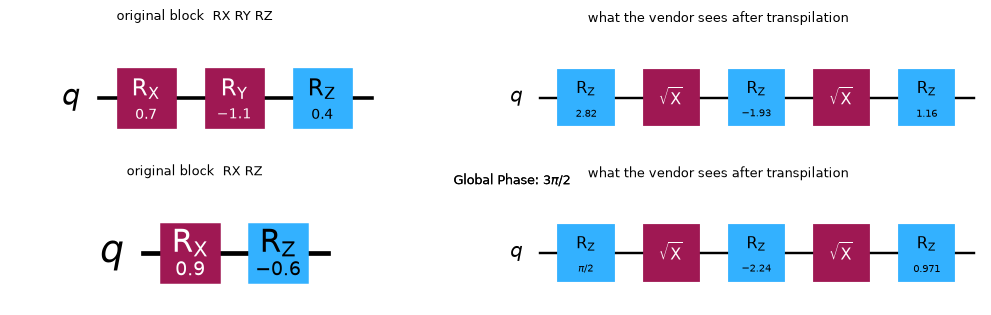

template XYZ: vectorised ZSX angles == qiskit.transpile angles on 200 random blocks (0 mismatches)


template  XZ: vectorised ZSX angles == qiskit.transpile angles on 200 random blocks (0 mismatches)


In [4]:
def wrap(a):
    """Map angles to (-pi, pi]; Qiskit prints RZ angles in this range (a 2*pi shift changes only the global phase)."""
    return (a + np.pi) % (2 * np.pi) - np.pi

def rot_np(g, t):
    """Batch of single-qubit rotations RX/RY/RZ(t) as (N,2,2) complex matrices."""
    t = np.asarray(t, dtype=float)
    c, s = np.cos(t / 2), np.sin(t / 2)
    z = np.zeros_like(t, dtype=complex)
    if g == "x":   m = [[c + 0j, -1j * s], [-1j * s, c + 0j]]
    elif g == "y": m = [[c + 0j, -s + 0j], [s + 0j, c + 0j]]
    else:          m = [[np.exp(-1j * t / 2), z], [z, np.exp(1j * t / 2)]]
    m = np.array(m)
    return m.transpose(2, 0, 1) if t.ndim > 0 else m

def seq_unitary(seq, th):
    """Unitary of the gate sequence `seq` (e.g. 'xyz' = RX first, then RY, then RZ); th has shape (N, len(seq))."""
    th = np.atleast_2d(th); U = None
    for j, g in enumerate(seq):
        R = rot_np(g, th[:, j]); U = R if U is None else R @ U
    return U

def zsx_params(U):
    """Vectorised copy of Qiskit's ZSX Euler decomposition: the three RZ angles (time order) of RZ SX RZ SX RZ."""
    det = np.linalg.det(U); da = np.angle(det)
    theta = 2 * np.arctan2(np.abs(U[:, 1, 0]), np.abs(U[:, 0, 0]))
    a1 = np.angle(U[:, 1, 1]); a2 = np.angle(U[:, 1, 0])
    phi = a1 + a2 - da; lam = a1 - a2
    return np.stack([wrap(lam), wrap(theta + np.pi), wrap(phi + np.pi)], 1)

def template_circuit(seq, th):
    qc = QuantumCircuit(1)
    for g, t in zip(seq, th):
        getattr(qc, "r" + g)(float(t), 0)
    return qc

def vendor_transpile(qc, n, seed=SEED, level=OPT_LEVEL):
    """The vendor's transpiler: linear coupling map, IBM basis gates, trivial initial layout."""
    return transpile(qc, basis_gates=BASIS_GATES, coupling_map=CouplingMap.from_line(n) if n > 1 else None,
                     optimization_level=level, initial_layout=list(range(n)) if n > 1 else None, seed_transpiler=seed)

# ---- Fig. 2: the two templates before and after transpilation ----
demo = {"xyz": [0.7, -1.1, 0.4], "xz": [0.9, -0.6]}
fig, axes = plt.subplots(2, 2, figsize=(12, 3.6))
for r, (seq, th) in enumerate(demo.items()):
    orig = template_circuit(seq, th); tc = vendor_transpile(orig, 1)
    orig.draw("mpl", ax=axes[r, 0]); axes[r, 0].set_title(f"original block  R{seq[0].upper()}" + "".join(" R" + g.upper() for g in seq[1:]), fontsize=10)
    tc.draw("mpl", ax=axes[r, 1]); axes[r, 1].set_title("what the vendor sees after transpilation", fontsize=10)
    for ax in axes[r]: ax.grid(False)
plt.tight_layout(); plt.show()

# ---- assertion: vectorised ZSX == qiskit.transpile on random blocks (circular comparison of the RZ angles) ----
chk_rng = np.random.default_rng(SEED)
for seq in ["xyz", "xz"]:
    th = chk_rng.uniform(-np.pi, np.pi, (200, len(seq)))
    P = zsx_params(seq_unitary(seq, th)); bad = 0
    for i in range(len(th)):
        tc = vendor_transpile(template_circuit(seq, th[i]), 1)
        rz = [float(g.operation.params[0]) for g in tc.data if g.operation.name == "rz"]
        bad += int(len(rz) != 3 or np.abs(wrap(np.array(rz) - P[i])).max() > 1e-8)
    assert bad == 0, f"vectorised ZSX differs from qiskit.transpile on {bad} blocks of template {seq}"
    print(f"template {seq.upper():>3}: vectorised ZSX angles == qiskit.transpile angles on 200 random blocks (0 mismatches)")

## 2. The classifiers of Table III and the MNIST data

**Data.** MNIST (the paper's data set, Hugging Face `ylecun/mnist`, parquet; OpenML as fallback), cached in `DATA_DIR`. The data set is public; if you
ever point the loader at a gated Hugging Face data set you need your own token in Colab *Secrets* (`HF_TOKEN`) or in the environment variable `HF_TOKEN`; the token
is read only from there and is never printed or stored.
The paper picks "labels as per the capacity of the QML model": we use digits 0 vs 1 for the 1-qubit classifier and digits 0 to 3 for the others.

**Pre-processing (fitted on the training images only).** pixels / 255, `PCA(n_qubits)`, `MinMaxScaler((0, pi))`, test angles clipped to [0, pi]; feature *i* is the angle of an `RY`
on qubit *i*.

**Classifiers.** For every qubit/layer pair of Table III (see the choice table above): `RY(x_i)` encoding, then `L` layers of rotation blocks on every qubit and a chain of `CX`
gates, read-out of the first 1 or 2 qubits. The *trained part* (everything except the `RY` encoding) is the circuit that is sent to the vendor.

In [5]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN (only needed for gated data sets)
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def load_mnist():
    """MNIST as uint8 images + labels. Primary source Hugging Face (parquet), fallback OpenML. Cached in DATA_DIR."""
    cache = os.path.join(DATA_DIR, "mnist.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["Xtr"], z["ytr"], z["Xte"], z["yte"]
    try:
        import huggingface_hub as hf
        from PIL import Image
        out = {}
        for split in ["train", "test"]:
            p = hf.hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN or None)
            d = pd.read_parquet(p)
            X = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in d["image"]]).astype(np.uint8)
            out[split] = (X, d["label"].to_numpy())
        Xtr, ytr, Xte, yte = out["train"] + out["test"]
    except Exception as e:
        print("Hugging Face download failed (", repr(e)[:90], ") -> OpenML fallback")
        from sklearn.datasets import fetch_openml
        d = fetch_openml("mnist_784", version=1, as_frame=False, parser="liac-arff", data_home=DATA_DIR)
        X = d.data.reshape(-1, 28, 28).astype(np.uint8); y = d.target.astype(int)
        Xtr, ytr, Xte, yte = X[:60000], y[:60000], X[60000:], y[60000:]
    np.savez_compressed(cache, Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte)
    return Xtr, ytr, Xte, yte

Xtr_all, ytr_all, Xte_all, yte_all = load_mnist()
print("MNIST train", Xtr_all.shape, "test", Xte_all.shape, "| train class counts", np.bincount(ytr_all).tolist())

MNIST train (60000, 28, 28) test (10000, 28, 28) | train class counts [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


In [6]:
# ---------- the ten classifiers of Table III ----------
ARCHS = [  # (name, qubits, layers, rotation template per qubit and layer)
    ("1Q;3-layer", 1, 3, "xyz"), ("2Q;1-layer", 2, 1, "xyz"), ("2Q;2-layer", 2, 2, "xyz"), ("2Q;3-layer", 2, 3, "xyz"),
    ("4Q;1-layer", 4, 1, "xz"),  ("4Q;2-layer", 4, 2, "xz"),  ("4Q;3-layer", 4, 3, "xz"),
    ("8Q;1-layer", 8, 1, "xz"),  ("8Q;2-layer", 8, 2, "xz"),  ("8Q;3-layer", 8, 3, "xz")]
PAPER_NPARAMS = {"1Q;3-layer": 4, "2Q;1-layer": 6, "2Q;2-layer": 12, "2Q;3-layer": 18, "4Q;1-layer": 8, "4Q;2-layer": 16, "4Q;3-layer": 24,
                 "8Q;1-layer": 16, "8Q;2-layer": 32, "8Q;3-layer": 48}

def arch_gate_list(n, L, seq):
    """Ordered gate list of the trained part: ('x'|'y'|'z', qubit, param_index) rotations and ('cx', control, target)."""
    gl, pi = [], 0
    for l in range(L):
        for q in range(n):
            if n == 1:                       # 1 qubit: one rotation per layer (RX, RY, RZ)
                gl.append((seq[l % len(seq)], q, pi)); pi += 1
            else:
                for g in seq:
                    gl.append((g, q, pi)); pi += 1
        for q in range(n - 1):
            gl.append(("cx", q, q + 1))
    return gl

def n_params(n, L, seq):
    return sum(1 for g in arch_gate_list(n, L, seq) if g[0] != "cx")

def segment_index(n, L, seq, q, l):
    """Indices (into the parameter vector) of the rotation block of qubit q in layer l (1 qubit: the whole circuit is one block)."""
    k = len(seq)
    return list(range(l * n * k + q * k, l * n * k + q * k + k)) if n > 1 else list(range(0, L))

def pl_apply_trained(params, gl):
    for g, a, b in gl:
        if g == "cx": qml.CNOT(wires=[a, b])
        else: {"x": qml.RX, "y": qml.RY, "z": qml.RZ}[g](params[b], wires=a)

def make_qnode(n, gl, n_out):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="autograd", diff_method="backprop")
    def circuit(params, x):
        for q in range(n):
            qml.RY(x[..., q], wires=q)               # angle encoding = state preparation (stripped by the adversary)
        pl_apply_trained(params, gl)
        return qml.probs(wires=list(range(n_out)))
    return circuit

def qiskit_trained(params, gl, n):
    """Qiskit twin of the trained part (what the user sends to the vendor, before transpilation)."""
    qc = QuantumCircuit(n)
    for g, a, b in gl:
        if g == "cx": qc.cx(a, b)
        else: getattr(qc, "r" + g)(float(params[b]), a)
    return qc

def prep_data(n, C, n_tr, n_te, seed):
    """Balanced MNIST subset of digits 0..C-1, pixels/255 -> PCA(n) -> MinMax to [0, pi]; every transform fitted on the training split only."""
    r = np.random.default_rng(seed)
    def pick(X, y, m):
        idx = np.concatenate([r.choice(np.where(y == c)[0], m // C, replace=False) for c in range(C)]); r.shuffle(idx)
        return X[idx].reshape(len(idx), -1) / 255.0, y[idx]
    a, ya = pick(Xtr_all, ytr_all, n_tr); b, yb = pick(Xte_all, yte_all, n_te)
    pca = PCA(n_components=n, random_state=SEED).fit(a)
    ra = pca.transform(a); rb = pca.transform(b)
    sc = MinMaxScaler((0, np.pi)).fit(ra)
    return dict(Xtr=np.clip(sc.transform(ra), 0, np.pi), ytr=ya, Xte=np.clip(sc.transform(rb), 0, np.pi), yte=yb, raw_tr=ra, raw_te=rb, pca=pca)

# ---- fast exact simulator used ONLY for the gradient-descent loops (PennyLane's per-gate autograd is ~5x slower) ----
def tens_gate(g, th):
    """RX / RY / RZ(th) as complex matrices; th may be a vector of angles -> (len, 2, 2)."""
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    if g == "x": return torch.stack([torch.stack([c + 0j, -1j * s], -1), torch.stack([-1j * s, c + 0j], -1)], -2)
    if g == "y": return torch.stack([torch.stack([c + 0j, -s + 0j], -1), torch.stack([s + 0j, c + 0j], -1)], -2)
    z = torch.zeros_like(th); e = lambda a: torch.polar(torch.ones_like(a), a)
    return torch.stack([torch.stack([e(-th / 2), z + 0j], -1), torch.stack([z + 0j, e(th / 2)], -1)], -2)

class FastSim:
    """Layer-fused state-vector simulator of the trained architectures (PyTorch, complex128, autograd).
    One layer = kron of the n rotation blocks, then the CX chain as an index permutation (wire 0 = most significant bit, like PennyLane)."""
    def __init__(self, n, L, seq):
        self.n, self.L, self.seq = n, L, seq
        idx = np.arange(2 ** n); bits = (idx[:, None] >> np.arange(n - 1, -1, -1)) & 1
        for q in range(n - 1): bits[:, q + 1] ^= bits[:, q]                  # CX(0,1) CX(1,2) ... applied in this order
        self.inv = torch.argsort(torch.tensor((bits * (1 << np.arange(n - 1, -1, -1))).sum(1)))
    def probs(self, params, x, n_out):
        n, L, seq = self.n, self.L, self.seq; k = len(seq); B = x.shape[0]; psi = None
        for q in range(n):                                                   # RY(x_q)|0> product state
            v = torch.stack([torch.cos(x[:, q] / 2), torch.sin(x[:, q] / 2)], -1).to(torch.complex128)
            psi = v if psi is None else (psi.unsqueeze(-1) * v.reshape(B, *([1] * (psi.dim() - 1)), 2))
        psi = psi.reshape(B, -1)
        if n == 1:
            U = None
            for l in range(L):
                M = tens_gate(seq[l % len(seq)], params[l]); U = M if U is None else M @ U
            psi = psi @ U.T
        else:
            for l in range(L):
                p = params[l * n * k:(l + 1) * n * k].reshape(n, k); blk = None
                for j, g in enumerate(seq):
                    M = tens_gate(g, p[:, j]); blk = M if blk is None else M @ blk
                U = functools.reduce(torch.kron, [blk[q] for q in range(n)])
                psi = (psi @ U.T)[:, self.inv]
        pr = psi.abs() ** 2
        return pr.reshape(B, 2 ** n_out, -1).sum(-1) if n_out < n else pr

def train_gd(sim, params, X, y, n_out, epochs, lr=QML_LR, bs=BS, seed=SEED):
    """Plain mini-batch gradient descent (theta <- theta - 0.05 * grad) on the MSE between the class probabilities and one-hot labels (paper Sec. V-A)."""
    r = np.random.default_rng(seed)
    th = torch.tensor(np.asarray(params, dtype=float), requires_grad=True); opt = torch.optim.SGD([th], lr=lr)
    Xt = torch.tensor(X); Y1 = torch.tensor(np.eye(2 ** n_out)[y])
    for ep in range(epochs):
        idx = r.permutation(len(X))
        for s in range(0, len(X), bs):
            b = idx[s:s + bs]
            loss = ((sim.probs(th, Xt[b], n_out) - Y1[b]) ** 2).sum(1).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return th.detach().numpy().copy()

def accuracy(circuit, params, X, y, C):
    pr = np.asarray(circuit(pnp.array(params, requires_grad=False), pnp.array(X, requires_grad=False)))
    return float((pr[:, :C].argmax(1) == y).mean())

for name, n, L, seq in ARCHS:
    print(f"{name:11s} qubits {n}  layers {L}  template {seq.upper():3s}  trainable parameters {n_params(n, L, seq):2d} (paper lists {PAPER_NPARAMS[name]})")

1Q;3-layer  qubits 1  layers 3  template XYZ  trainable parameters  3 (paper lists 4)
2Q;1-layer  qubits 2  layers 1  template XYZ  trainable parameters  6 (paper lists 6)
2Q;2-layer  qubits 2  layers 2  template XYZ  trainable parameters 12 (paper lists 12)
2Q;3-layer  qubits 2  layers 3  template XYZ  trainable parameters 18 (paper lists 18)
4Q;1-layer  qubits 4  layers 1  template XZ   trainable parameters  8 (paper lists 8)
4Q;2-layer  qubits 4  layers 2  template XZ   trainable parameters 16 (paper lists 16)
4Q;3-layer  qubits 4  layers 3  template XZ   trainable parameters 24 (paper lists 24)
8Q;1-layer  qubits 8  layers 1  template XZ   trainable parameters 16 (paper lists 16)
8Q;2-layer  qubits 8  layers 2  template XZ   trainable parameters 32 (paper lists 32)
8Q;3-layer  qubits 8  layers 3  template XZ   trainable parameters 48 (paper lists 48)


### 2b. The users train their classifiers (the victims)

Every classifier is trained for `EPOCHS` epochs of mini-batch gradient descent (lr 0.05, MSE) from small random parameters. The gradient loops run on a small PyTorch state-vector simulator (`FastSim`: one layer =
Kronecker product of the rotation blocks, the CX chain as an index permutation) because PennyLane's per-gate autograd is about five times slower on a CPU; before training, the notebook **asserts that `FastSim` and the
PennyLane QNode give the same probabilities** (to 1e-10), and all accuracies are computed with the PennyLane QNode. These are the **victim models**: the next sections steal their parameters
from the transpiled circuits. The original (un-stolen) accuracy on the held-out MNIST test images is the reference for the "accuracy error" of Table III.

In [7]:
VICT = {}                       # (arch name, seed) -> dict
t0 = time.time()
for seed in SEEDS:
    for name, n, L, seq in ARCHS:
        C = 2 if n == 1 else 4; n_out = 1 if C == 2 else 2
        D = prep_data(n, C, N_TRAIN, N_TEST, seed)
        gl = arch_gate_list(n, L, seq); P = n_params(n, L, seq)
        circuit = make_qnode(n, gl, n_out)
        p0 = np.clip(np.random.default_rng(seed + 1000 * n + L).normal(0, 0.5, P), -np.pi, np.pi)
        t1 = time.time(); sim = FastSim(n, L, seq)
        d_sim = np.abs(np.asarray(circuit(pnp.array(p0), pnp.array(D["Xte"][:20], requires_grad=False))) - sim.probs(torch.tensor(p0), torch.tensor(D["Xte"][:20]), n_out).numpy()).max()
        assert d_sim < 1e-10, f"fast simulator differs from the PennyLane circuit ({d_sim})"
        theta = train_gd(sim, p0, D["Xtr"], D["ytr"], n_out, EPOCHS, seed=seed)
        acc0 = accuracy(circuit, p0, D["Xte"], D["yte"], C); acc1 = accuracy(circuit, theta, D["Xte"], D["yte"], C)
        VICT[(name, seed)] = dict(name=name, n=n, L=L, seq=seq, C=C, n_out=n_out, D=D, gl=gl, circuit=circuit, sim=sim, theta0=p0, theta=theta, acc_init=acc0, acc=acc1)
        print(f"seed {seed} {name:11s} test accuracy: initial {acc0:.3f} -> trained {acc1:.3f}   |theta| max {np.abs(theta).max():.2f}   ({time.time()-t1:5.1f} s)", flush=True)
print(f"victims trained in {time.time()-t0:.0f} s")

seed 42 1Q;3-layer  test accuracy: initial 1.000 -> trained 0.998   |theta| max 0.49   ( 25.2 s)


seed 42 2Q;1-layer  test accuracy: initial 0.422 -> trained 0.492   |theta| max 1.30   (  9.4 s)


seed 42 2Q;2-layer  test accuracy: initial 0.453 -> trained 0.750   |theta| max 1.57   ( 12.2 s)


seed 42 2Q;3-layer  test accuracy: initial 0.193 -> trained 0.730   |theta| max 1.68   ( 24.6 s)


seed 42 4Q;1-layer  test accuracy: initial 0.512 -> trained 0.512   |theta| max 0.90   ( 14.1 s)


...

seed 42 4Q;3-layer  test accuracy: initial 0.502 -> trained 0.770   |theta| max 1.44   ( 37.9 s)


seed 42 8Q;1-layer  test accuracy: initial 0.512 -> trained 0.512   |theta| max 1.00   ( 50.1 s)


seed 42 8Q;2-layer  test accuracy: initial 0.393 -> trained 0.530   |theta| max 1.56   (116.5 s)


seed 42 8Q;3-layer  test accuracy: initial 0.432 -> trained 0.790   |theta| max 1.95   (126.4 s)


victims trained in 446 s


## Dataset Exploration and Visualisation

The paper uses two kinds of data, and both are looked at here with **real observations only** (nothing invented):

1. **MNIST images**, the data of the classifiers that get stolen (Sec. V-A): shape, feature names, class counts, example digits, and a 2-D scatter of the
   *real training images* coloured by their true digit - first the raw PCA coordinates (fitted on the training split), then the same two coordinates scaled to the
   angles [0, pi] that are fed to the first two qubits.
2. **The transpilation data set** of the autoencoder (Sec. IV-B): the real rows `(x, y, z) -> transpiled RZ angles` produced by the vendor's transpiler, and the
   **transpiled victim circuits** themselves (gate-count features of all ten architectures, coloured by their ground-truth architecture).

MNIST training images: (60000, 28, 28) (60000 images of 28 x 28 pixels); test images: (10000, 28, 28)
features: 784 pixel intensities pixel_0 ... pixel_783 (uint8, 0..255);  original labels: digits 0..9
          0     1     2     3     4     5     6     7     8     9
train  5923  6742  5958  6131  5842  5421  5918  6265  5851  5949
test    980  1135  1032  1010   982   892   958  1028   974  1009
subsets used by the classifiers: {'1 qubit (digits 0-1)': [0, 1], '2/4/8 qubits (digits 0-3)': [0, 1, 2, 3]} | sampled per run: 600 training / 400 test images, balanced


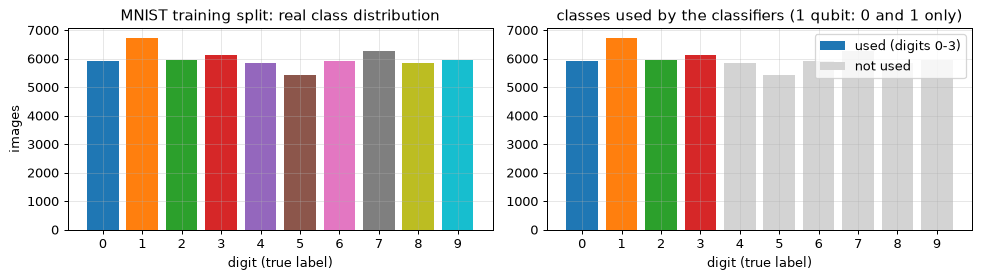

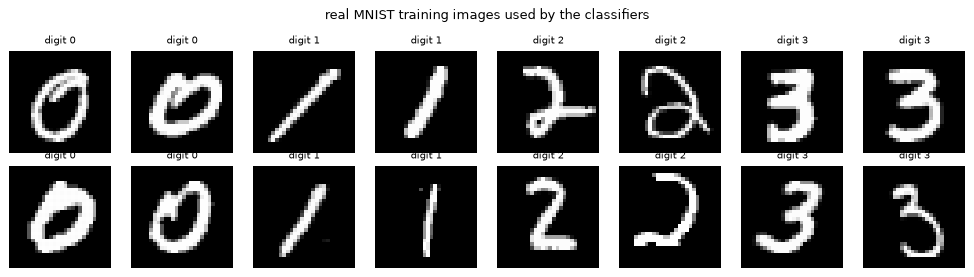

In [8]:
# ---- 1. MNIST: shape, features, labels, class counts ----
print("MNIST training images:", Xtr_all.shape, "(60000 images of 28 x 28 pixels); test images:", Xte_all.shape)
print("features: 784 pixel intensities pixel_0 ... pixel_783 (uint8, 0..255);  original labels: digits 0..9")
counts_tr = pd.Series(np.bincount(ytr_all), name="train"); counts_te = pd.Series(np.bincount(yte_all), name="test")
print(pd.concat([counts_tr, counts_te], axis=1).T.to_string())
used = {"1 qubit (digits 0-1)": [0, 1], "2/4/8 qubits (digits 0-3)": [0, 1, 2, 3]}
print("subsets used by the classifiers:", used, "| sampled per run:", f"{N_TRAIN} training / {N_TEST} test images, balanced")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
cols = plt.cm.tab10(np.arange(10))
axes[0].bar(range(10), counts_tr.values, color=cols); axes[0].set_xticks(range(10)); axes[0].set_xlabel("digit (true label)"); axes[0].set_ylabel("images")
axes[0].set_title("MNIST training split: real class distribution")
sub = np.isin(ytr_all, [0, 1, 2, 3])
axes[1].bar(range(10), np.where(np.arange(10) < 4, counts_tr.values, 0), color=cols, label="used (digits 0-3)")
axes[1].bar(range(10), np.where(np.arange(10) >= 4, counts_tr.values, 0), color="lightgrey", label="not used")
axes[1].set_xticks(range(10)); axes[1].set_xlabel("digit (true label)"); axes[1].set_title("classes used by the classifiers (1 qubit: 0 and 1 only)"); axes[1].legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 8, figsize=(11, 3.1))
r = np.random.default_rng(SEED)
for c in range(4):
    ids = r.choice(np.where(ytr_all == c)[0], 4, replace=False)
    for j, i in enumerate(ids):
        ax = axes[(j // 2) % 2, (c * 2 + j % 2)]; ax.imshow(Xtr_all[i], cmap="gray"); ax.set_title(f"digit {c}", fontsize=8); ax.axis("off")
plt.suptitle("real MNIST training images used by the classifiers", fontsize=10); plt.tight_layout(); plt.show()

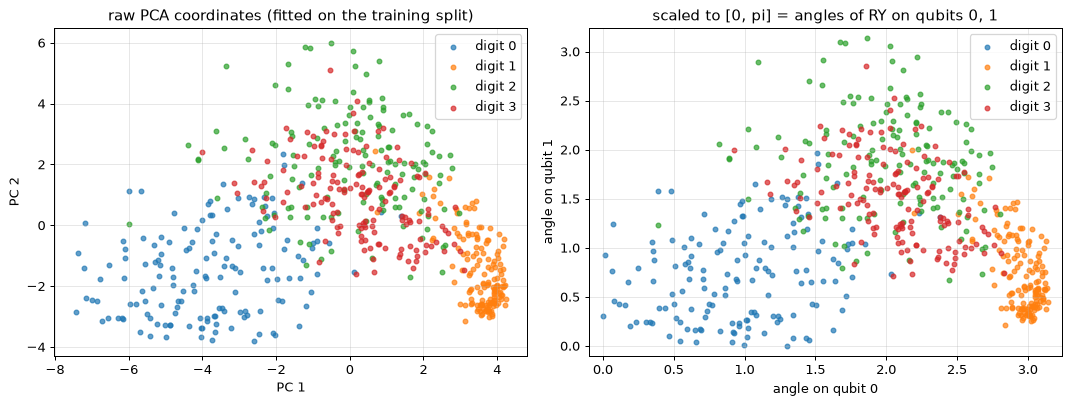

1-qubit task (digits 0/1): a single angle per image; mean angle digit 0 = 1.01 , digit 1 = 2.92


In [9]:
# ---- 2-D scatter of the real training images, coloured by the true digit (4-class task, PCA fitted on the training split) ----
v = VICT[("8Q;1-layer", SEEDS[0])]; D = v["D"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for c in range(4):
    m = D["ytr"] == c
    axes[0].scatter(D["raw_tr"][m, 0], D["raw_tr"][m, 1], s=14, alpha=0.7, color=cols[c], label=f"digit {c}")
    axes[1].scatter(D["Xtr"][m, 0], D["Xtr"][m, 1], s=14, alpha=0.7, color=cols[c], label=f"digit {c}")
axes[0].set_title("raw PCA coordinates (fitted on the training split)"); axes[0].set_xlabel("PC 1"); axes[0].set_ylabel("PC 2"); axes[0].legend()
axes[1].set_title("scaled to [0, pi] = angles of RY on qubits 0, 1"); axes[1].set_xlabel("angle on qubit 0"); axes[1].set_ylabel("angle on qubit 1")
axes[1].set_xlim(-0.1, np.pi + 0.1); axes[1].set_ylim(-0.1, np.pi + 0.1); axes[1].legend()
plt.tight_layout(); plt.show()
v1 = VICT[("1Q;3-layer", SEEDS[0])]["D"]
print("1-qubit task (digits 0/1): a single angle per image; mean angle digit 0 =", round(v1["Xtr"][v1["ytr"]==0, 0].mean(), 2), ", digit 1 =", round(v1["Xtr"][v1["ytr"]==1, 0].mean(), 2))

### The transpilation data set of the autoencoder

The rows of the autoencoder's data set are generated further below (section 4); here we look at the *real* rows already, for the `RX RY RZ` template with a coarse grid: the left
panel plots the transpiled middle angle `phi1` (an input of the autoencoder) against the original angle `y` (what it must output), coloured by the original `x`; the right panel shows the other two transpiled angles
`phi0`, `phi2` coloured by the original `z`. Every point is one real row of the data set, labelled by its ground-truth original angles.

transpilation data set (RX RY RZ template, step 0.3 for this plot): 9261 rows; input columns = transpiled RZ angles phi0, phi1, phi2; target columns = original angles x, y, z; ground-truth labels = the original angles
       x      y      z   phi0   phi1   phi2
0 -3.142 -3.142 -3.142  2.356 -3.142  0.785
1 -3.142 -3.142 -2.842  2.356 -3.142  1.085
2 -3.142 -3.142 -2.542  2.356 -3.142  1.385
3 -3.142 -3.142 -2.242  2.356 -3.142  1.685
4 -3.142 -3.142 -1.942  2.356 -3.142  1.985


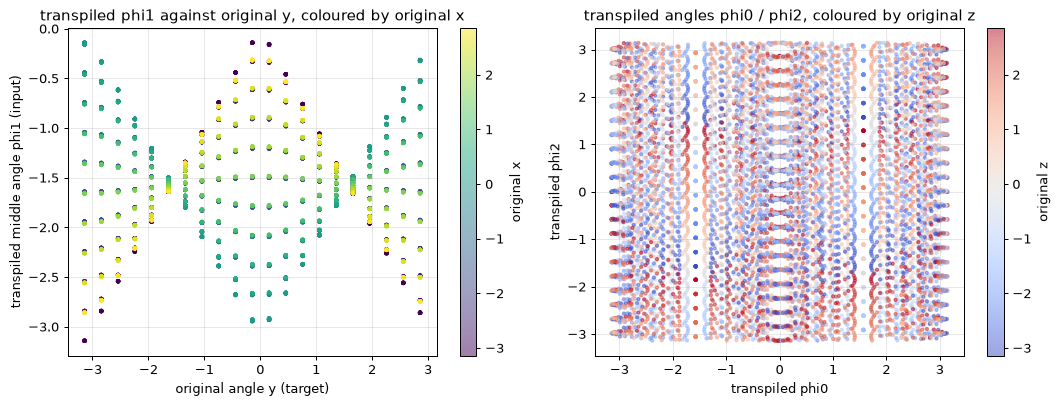

In [10]:
g = np.arange(-np.pi, np.pi, 0.3)
th_demo = np.stack([a.ravel() for a in np.meshgrid(g, g, g, indexing="ij")], 1)
P_demo = zsx_params(seq_unitary("xyz", th_demo))
print("transpilation data set (RX RY RZ template, step 0.3 for this plot):", th_demo.shape[0], "rows;",
      "input columns = transpiled RZ angles phi0, phi1, phi2; target columns = original angles x, y, z; ground-truth labels = the original angles")
print(pd.DataFrame(np.c_[th_demo[:5], P_demo[:5]], columns=["x", "y", "z", "phi0", "phi1", "phi2"]).round(3).to_string())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sc0 = axes[0].scatter(th_demo[:, 1], P_demo[:, 1], c=th_demo[:, 0], s=6, alpha=0.5, cmap="viridis"); axes[0].set_xlabel("original angle y (target)"); axes[0].set_ylabel("transpiled middle angle phi1 (input)")
axes[0].set_title("transpiled phi1 against original y, coloured by original x"); plt.colorbar(sc0, ax=axes[0], label="original x")
sc1 = axes[1].scatter(P_demo[:, 0], P_demo[:, 2], c=th_demo[:, 2], s=6, alpha=0.5, cmap="coolwarm"); axes[1].set_xlabel("transpiled phi0"); axes[1].set_ylabel("transpiled phi2")
axes[1].set_title("transpiled angles phi0 / phi2, coloured by original z"); plt.colorbar(sc1, ax=axes[1], label="original z")
plt.tight_layout(); plt.show()

gate-count features of the transpiled circuits: ['n_rz', 'n_sx', 'n_cx', 'depth', 'size', 'n_qubits', 'rz+sx on q0', 'rz+sx on q1', 'rz+sx on q2', 'rz+sx on q3', 'rz+sx on q4', 'rz+sx on q5', 'rz+sx on q6', 'rz+sx on q7']
transpiled circuits: 60 ( 10 trained victims + 50 random-parameter copies ) over 10 architectures
            n_rz  n_sx  n_cx  depth  size  n_qubits  rz+sx on q0  rz+sx on q1  rz+sx on q2  rz+sx on q3  rz+sx on q4  rz+sx on q5  rz+sx on q6  rz+sx on q7
1Q;3-layer     3     2     0      5     5         1            5            0            0            0            0            0            0            0
1Q;3-layer     3     2     0      5     5         1            5            0            0            0            0            0            0            0
1Q;3-layer     3     2     0      5     5         1            5            0            0            0            0            0            0            0
1Q;3-layer     3     2     0      5     5         1     

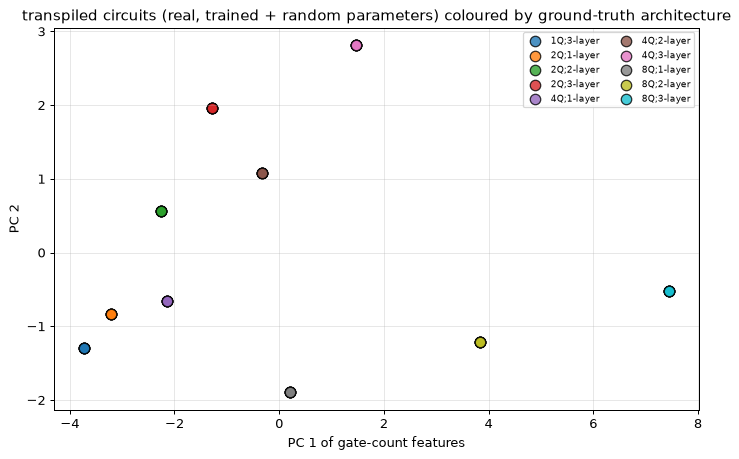

Reading: all circuits of one architecture land on the same point (the transpiled structure is fixed by the architecture, not by the parameter values): the architecture, i.e. the entanglement structure and the template of every block, is read from the circuit without any learning (paper Sec. III).


In [11]:
# ---- the transpiled victim circuits: gate-count features of all ten architectures, coloured by the ground-truth architecture ----
def parse_segments(tc, n):
    """Per qubit, the list of rotation blocks (consecutive single-qubit gates between two CX gates) of a transpiled circuit."""
    pend = [[] for _ in range(n)]; segs = [[] for _ in range(n)]
    for inst in tc.data:
        qs = [tc.find_bit(q).index for q in inst.qubits]; nm = inst.operation.name
        if nm == "cx":
            for q in qs:
                if pend[q]: segs[q].append(pend[q]); pend[q] = []
        elif nm != "barrier":
            pend[qs[0]].append(inst)
    for q in range(n):
        if pend[q]: segs[q].append(pend[q])
    return segs

def circuit_features(tc, n):
    ops = tc.count_ops()
    per_q = np.zeros(8)
    for inst in tc.data:
        if inst.operation.name in ("rz", "sx"): per_q[tc.find_bit(inst.qubits[0]).index] += 1
    return np.r_[ops.get("rz", 0), ops.get("sx", 0), ops.get("cx", 0), tc.depth(), tc.size(), n, per_q]

feat_names = ["n_rz", "n_sx", "n_cx", "depth", "size", "n_qubits"] + [f"rz+sx on q{i}" for i in range(8)]
rows, labs, kinds = [], [], []
for (name, seed), v in VICT.items():
    tc = vendor_transpile(qiskit_trained(v["theta"], v["gl"], v["n"]), v["n"]); v["tc"] = tc
    rows.append(circuit_features(tc, v["n"])); labs.append(name); kinds.append("trained victim")
    for k in range(5):                                  # five more circuits per architecture with fresh random parameters (same architecture)
        th = np.random.default_rng(seed * 100 + k).uniform(-np.pi, np.pi, len(v["theta"]))
        rows.append(circuit_features(vendor_transpile(qiskit_trained(th, v["gl"], v["n"]), v["n"]), v["n"])); labs.append(name); kinds.append("random parameters")
F = np.array(rows, dtype=float)
print("gate-count features of the transpiled circuits:", feat_names)
print("transpiled circuits:", F.shape[0], "(", len(VICT), "trained victims +", F.shape[0] - len(VICT), "random-parameter copies ) over", len(ARCHS), "architectures")
print(pd.DataFrame(F[:len(ARCHS)], columns=feat_names, index=labs[:len(ARCHS)]).astype(int).to_string())
Z = PCA(2, random_state=SEED).fit_transform((F - F.mean(0)) / (F.std(0) + 1e-9))
arch_names = [a[0] for a in ARCHS]; acol = plt.cm.tab10(np.arange(10))
fig, ax = plt.subplots(figsize=(8, 5.2))
for i, nm in enumerate(arch_names):
    m = np.array(labs) == nm
    ax.scatter(Z[m, 0], Z[m, 1], s=70, color=acol[i], edgecolor="k", label=nm, alpha=0.8)
ax.set_xlabel("PC 1 of gate-count features"); ax.set_ylabel("PC 2"); ax.legend(fontsize=7, ncol=2)
ax.set_title("transpiled circuits (real, trained + random parameters) coloured by ground-truth architecture")
plt.tight_layout(); plt.show()
print("Reading: all circuits of one architecture land on the same point (the transpiled structure is fixed by the architecture, not by the parameter values):",
      "the architecture, i.e. the entanglement structure and the template of every block, is read from the circuit without any learning (paper Sec. III).")

## Quantum Circuit Architecture

Every gate-based model of the paper is drawn here from the objects that are actually executed.

* **The classifiers** (PennyLane, the paper's framework): `qml.draw_mpl` of the QNode that is trained and evaluated, one drawing per distinct architecture (ten). Each drawing shows the `RY`
  angle encoding (state preparation, removed by the adversary), the trainable rotation blocks, the `CX` chain and the read-out (probabilities of the first 1 or 2 qubits).
* **What the vendor receives** (Qiskit): the transpiled trained part for two architectures, drawn with `circuit.draw("mpl")`.
* **Equivalence assertions**: the PennyLane trained part has the same unitary as the Qiskit circuit that is transpiled (up to a global phase), and the transpiled circuit has the same unitary as the original for all ten architectures.

Assumptions where the paper omits circuit details (encoding, entangler, read-out, 1-qubit layer) are listed in the choice table at the top; the circuit of one architecture is identical for all seeds.

architecture  qubits  depth  gates  trainable_params template  cx
  1Q;3-layer       1      4      4                 3      XYZ   0
  2Q;1-layer       2      5      9                 6      XYZ   1
  2Q;2-layer       2      9     16                12      XYZ   2
  2Q;3-layer       2     13     23                18      XYZ   3
  4Q;1-layer       4      6     15                 8       XZ   3
  4Q;2-layer       4     10     26                16       XZ   6
  4Q;3-layer       4     14     37                24       XZ   9
  8Q;1-layer       8     10     31                16       XZ   7
  8Q;2-layer       8     14     54                32       XZ  14
  8Q;3-layer       8     18     77                48       XZ  21
(depth and gate count include the RY encoding layer; the cx column counts the CNOTs of the trained part)


Matplotlib is building the font cache; this may take a moment.


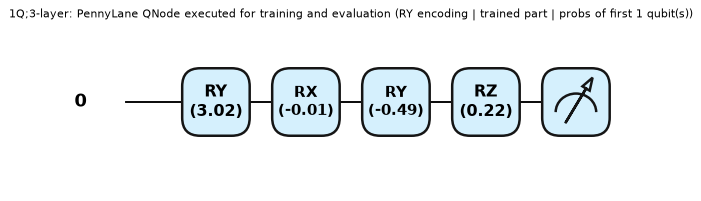

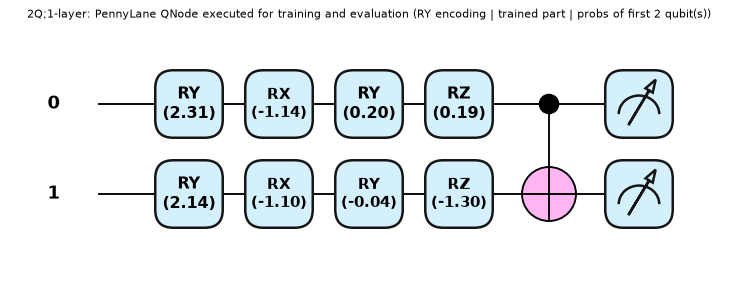

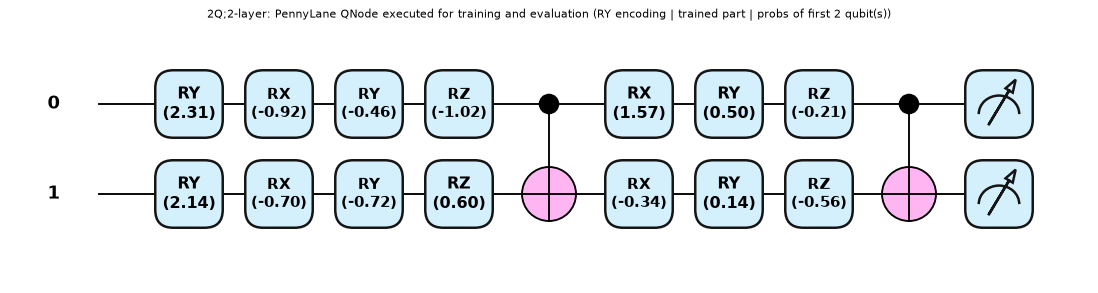

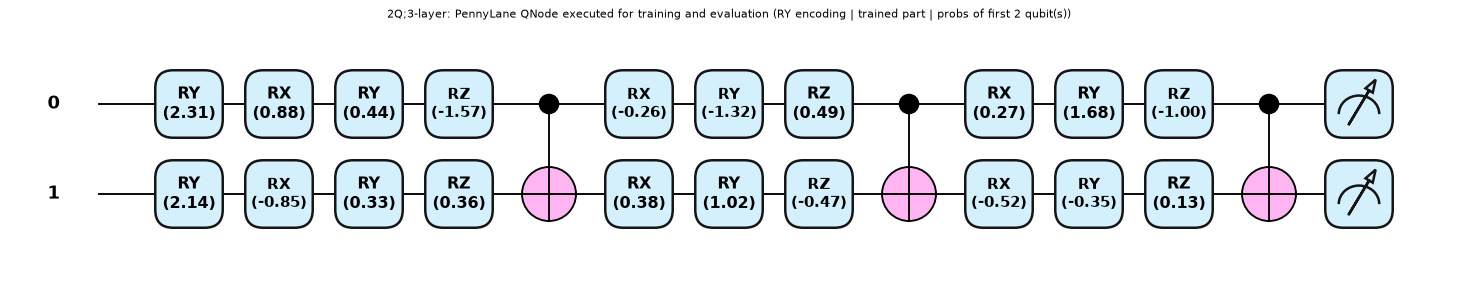

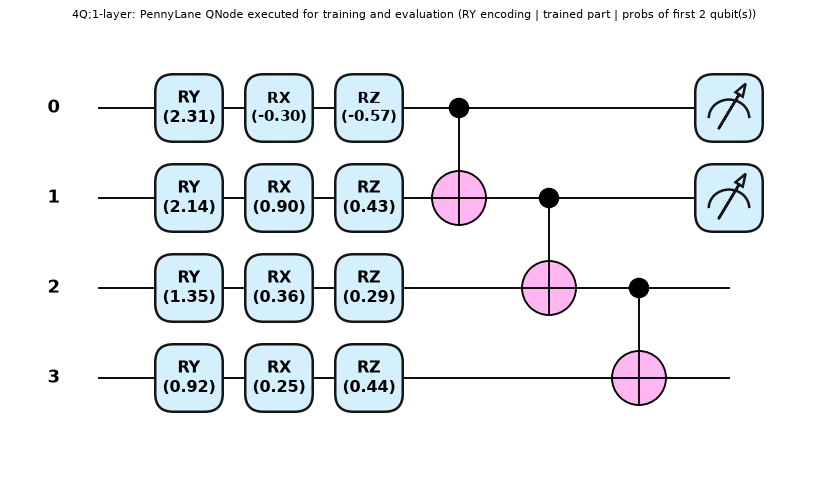

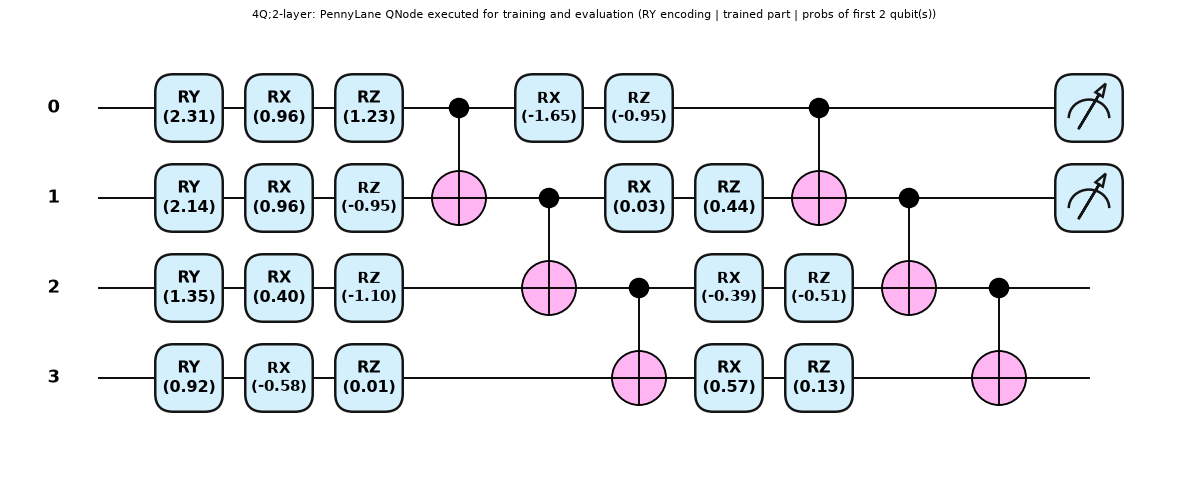

Matplotlib is building the font cache; this may take a moment.


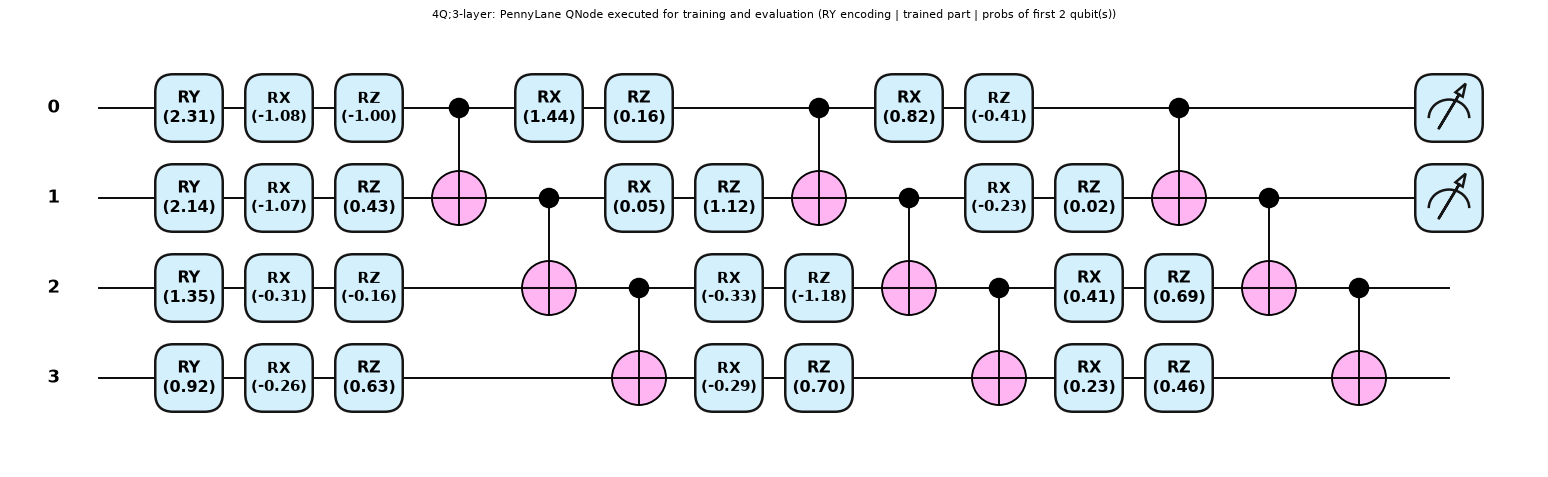

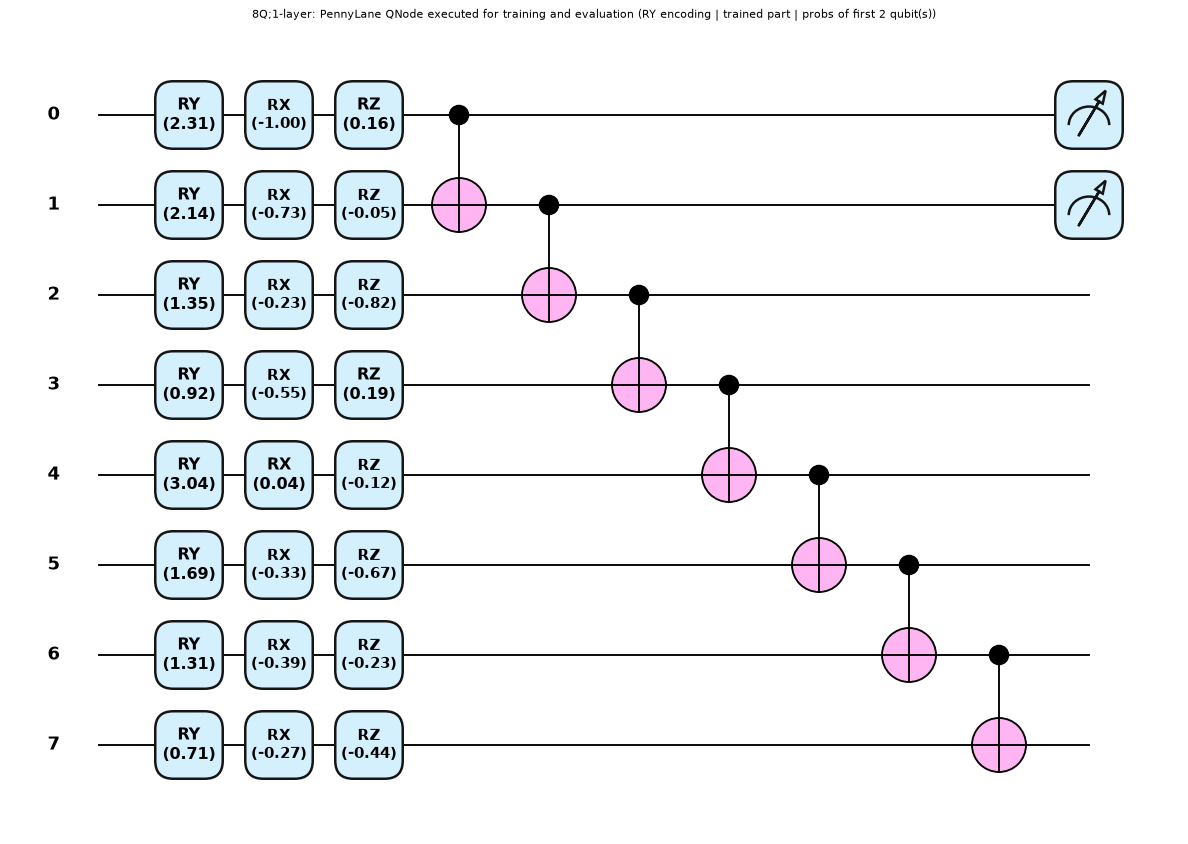

Matplotlib is building the font cache; this may take a moment.


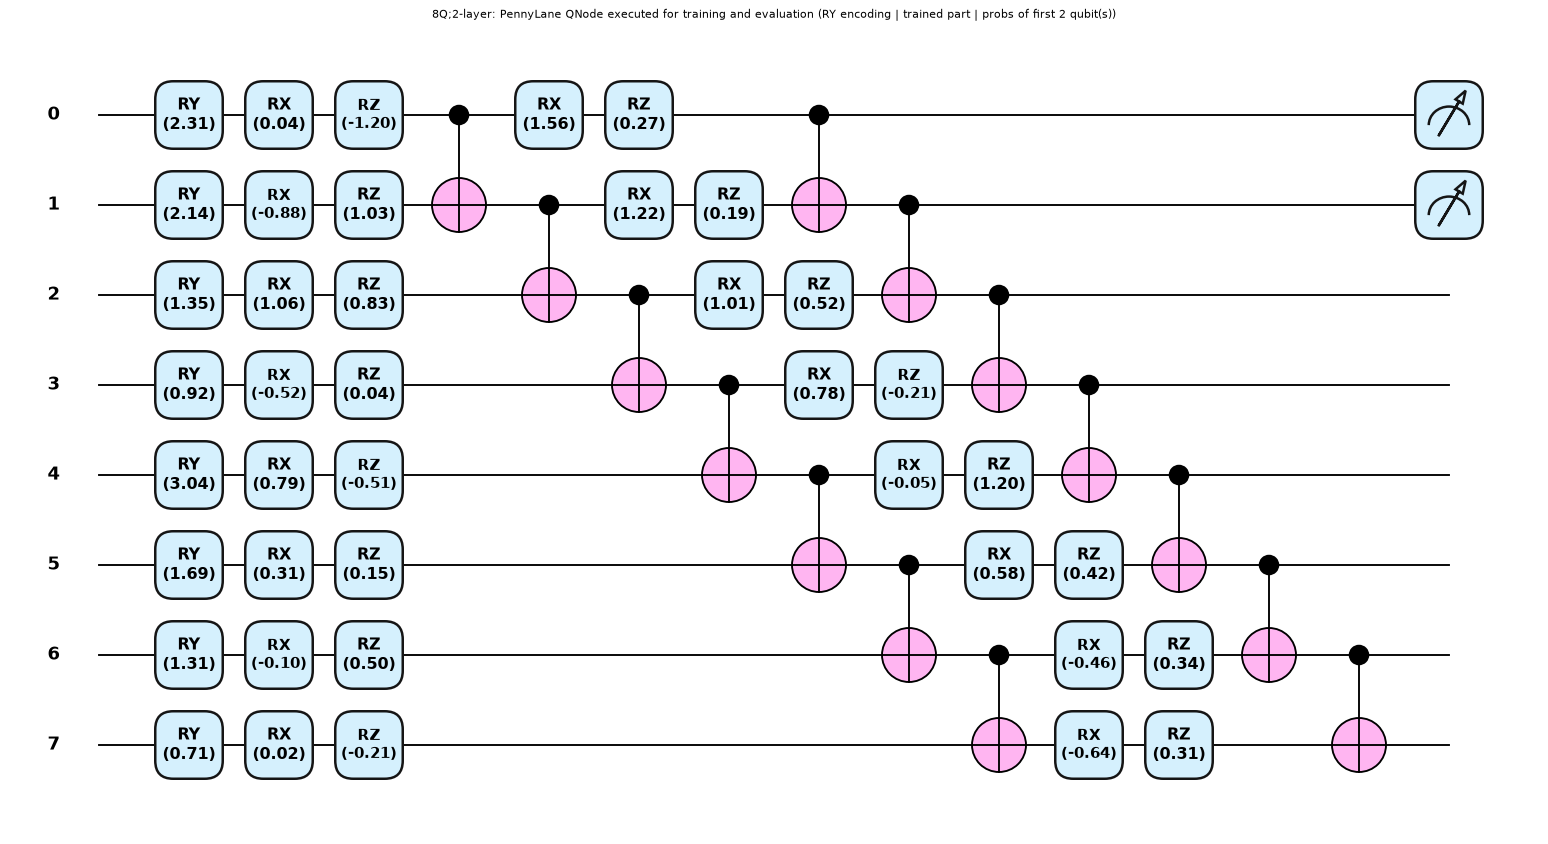

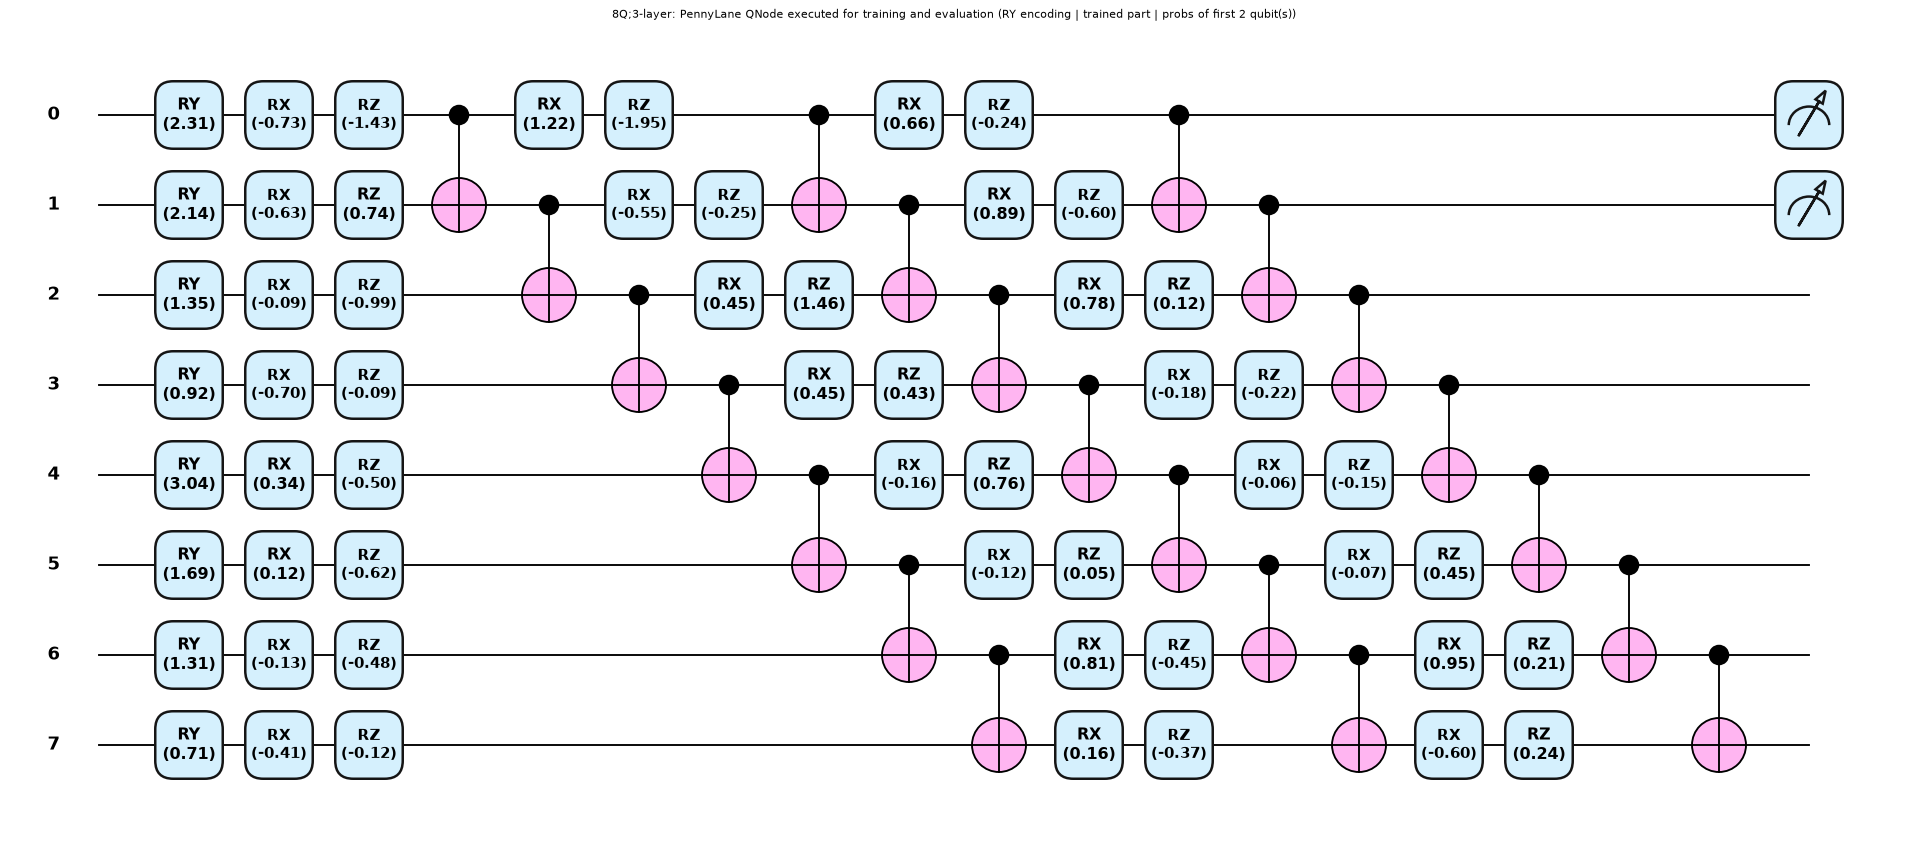

In [12]:
# ---- circuit properties + PennyLane drawings (one per architecture, trained parameters of the first seed) ----
prop = []
for name, n, L, seq in ARCHS:
    v = VICT[(name, SEEDS[0])]
    x0 = pnp.array(v["D"]["Xte"][0], requires_grad=False)
    spec = qml.specs(v["circuit"])(pnp.array(v["theta"]), x0)["resources"]
    prop.append(dict(architecture=name, qubits=n, depth=spec.depth, gates=spec.num_gates, trainable_params=len(v["theta"]), template=seq.upper(), cx=sum(1 for g in v["gl"] if g[0] == "cx")))
print(pd.DataFrame(prop).to_string(index=False))
print("(depth and gate count include the RY encoding layer; the cx column counts the CNOTs of the trained part)")

for name, n, L, seq in ARCHS:
    v = VICT[(name, SEEDS[0])]
    fig, ax = qml.draw_mpl(v["circuit"], decimals=2, style="pennylane")(pnp.array(v["theta"]), pnp.array(v["D"]["Xte"][0], requires_grad=False))
    fig.suptitle(f"{name}: PennyLane QNode executed for training and evaluation (RY encoding | trained part | probs of first {v['n_out']} qubit(s))", fontsize=9, y=1.02)
    plt.show()

2Q;1-layer: transpiled circuit  qubits 2  depth 6  size 11  ops {'rz': 6, 'sx': 4, 'cx': 1}  (linear coupling map, basis ['id', 'x', 'sx', 'cx', 'rz'], level 1)


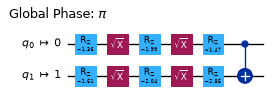

4Q;1-layer: transpiled circuit  qubits 4  depth 8  size 23  ops {'rz': 12, 'sx': 8, 'cx': 3}  (linear coupling map, basis ['id', 'x', 'sx', 'cx', 'rz'], level 1)


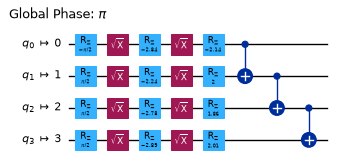

In [13]:
# ---- what the vendor receives: transpiled trained part (Qiskit), two architectures ----
for name in ["2Q;1-layer", "4Q;1-layer"]:
    v = VICT[(name, SEEDS[0])]
    print(f"{name}: transpiled circuit  qubits {v['n']}  depth {v['tc'].depth()}  size {v['tc'].size()}  ops {dict(v['tc'].count_ops())}  (linear coupling map, basis {BASIS_GATES}, level {OPT_LEVEL})")
    from IPython.display import display
    display(v["tc"].draw("mpl", fold=40, scale=0.55))

In [14]:
# ---- equivalence assertions ----
def pl_unitary(theta, gl, n):
    return np.array(qml.matrix(lambda: pl_apply_trained(theta, gl), wire_order=list(range(n)))())

def overlap(A, B):
    return abs(np.trace(A.conj().T @ B)) / A.shape[0]

eq = []
for name, n, L, seq in ARCHS:
    v = VICT[(name, SEEDS[0])]
    U_pl = pl_unitary(v["theta"], v["gl"], n)                                   # PennyLane: wire 0 = most significant qubit
    qc = qiskit_trained(v["theta"], v["gl"], n)
    U_q = Operator(qc.reverse_bits()).data                                      # Qiskit is little endian -> reverse
    U_tr = Operator(v["tc"].reverse_bits()).data
    o1, o2 = overlap(U_pl, U_q), overlap(U_q, U_tr)
    assert o1 > 1 - 1e-9, f"{name}: PennyLane and Qiskit circuits differ ({o1})"
    assert o2 > 1 - 1e-9, f"{name}: transpiled circuit differs from the original ({o2})"
    xs = v["D"]["Xte"][:50]
    d_fast = np.abs(np.asarray(v["circuit"](pnp.array(v["theta"]), pnp.array(xs, requires_grad=False))) - v["sim"].probs(torch.tensor(v["theta"]), torch.tensor(xs), v["n_out"]).numpy()).max()
    assert d_fast < 1e-10, f"{name}: FastSim differs from the PennyLane QNode ({d_fast})"
    eq.append(dict(architecture=name, pennylane_vs_qiskit=o1, original_vs_transpiled=o2, max_prob_diff_FastSim_vs_PennyLane=d_fast))
print(pd.DataFrame(eq).to_string(index=False, float_format=lambda x: f"{x:.12g}"))
print("All ten architectures: |tr(U_A^dagger U_B)| / 2^n = 1 (equal up to a global phase): the drawn PennyLane circuit, its Qiskit twin and the transpiled circuit implement the same unitary;",
      "the FastSim used for the gradient loops gives the PennyLane probabilities (trained parameters, 50 test images).")

architecture  pennylane_vs_qiskit  original_vs_transpiled  max_prob_diff_FastSim_vs_PennyLane
  1Q;3-layer                    1                       1                    4.4408920985e-16
  2Q;1-layer                    1                       1                   3.88578058619e-16
  2Q;2-layer                    1                       1                    4.4408920985e-16
  2Q;3-layer                    1                       1                   5.55111512313e-16
  4Q;1-layer                    1                       1                   5.55111512313e-16
  4Q;2-layer                    1                       1                   5.55111512313e-16
  4Q;3-layer                    1                       1                   7.77156117238e-16
  8Q;1-layer                    1                       1                    4.4408920985e-16
  8Q;2-layer                    1                       1                   3.88578058619e-16
  8Q;3-layer                    1                       1   

## 3. The autoencoder of Tables I and II

Encoder (Table I): `Dense 256 (ReLU) - BatchNorm - Dropout 0.3 - Dense 128 (ReLU) - BatchNorm - Dropout 0.3 - Dense 64 (ReLU) - Dense 32 (ReLU) - Dense 16 (ReLU, latent)`.
Decoder (Table II): `Dense 32 - BN - Dropout - Dense 64 - BN - Dropout - Dense 128 - Dense 256 (all ReLU) - Dense k` (linear output). The input has the
transpiled `RZ` angles (3 values here), the output the original angles (3 for `RX RY RZ`, 2 for `RX RZ`). The code asserts that the parameter counts equal the ones printed in the tables
(46 320 for the encoder; 45 155 for the decoder with k = 3).

In [15]:
def build_ae(k_in, k_out):
    inp = keras.Input((k_in,), name="transpiled_angles")
    x = layers.Dense(256, activation="relu")(inp); x = layers.BatchNormalization()(x); x = layers.Dropout(AE_DROPOUT)(x)
    x = layers.Dense(128, activation="relu")(x);   x = layers.BatchNormalization()(x); x = layers.Dropout(AE_DROPOUT)(x)
    x = layers.Dense(64, activation="relu")(x); x = layers.Dense(32, activation="relu")(x)
    z = layers.Dense(16, activation="relu", name="latent")(x)
    encoder = keras.Model(inp, z, name="encoder")
    zin = keras.Input((16,))
    y = layers.Dense(32, activation="relu")(zin);  y = layers.BatchNormalization()(y); y = layers.Dropout(AE_DROPOUT)(y)
    y = layers.Dense(64, activation="relu")(y);    y = layers.BatchNormalization()(y); y = layers.Dropout(AE_DROPOUT)(y)
    y = layers.Dense(128, activation="relu")(y); y = layers.Dense(256, activation="relu")(y)
    decoder = keras.Model(zin, layers.Dense(k_out, name="original_angles")(y), name="decoder")
    ae = keras.Model(inp, decoder(encoder(inp)), name="autoencoder")
    return ae, encoder, decoder

ae3, enc3, dec3 = build_ae(3, 3)
paper_enc = [1024, 1024, 0, 32896, 512, 0, 8256, 2080, 528]; paper_dec = [544, 128, 0, 2112, 256, 0, 8320, 33024, 771]
rows = []
for model, paper in [(enc3, paper_enc), (dec3, paper_dec)]:
    lays = [l for l in model.layers if not isinstance(l, keras.layers.InputLayer)]
    for l, pp in zip(lays, paper):
        rows.append(dict(model=model.name, layer=l.__class__.__name__, output_shape=str(l.output.shape[1:]), params=l.count_params(), paper_params=pp))
tab = pd.DataFrame(rows); print(tab.to_string(index=False))
assert (tab.params == tab.paper_params).all(), "layer parameter counts differ from Tables I/II"
assert enc3.count_params() == sum(paper_enc) and dec3.count_params() == sum(paper_dec)
print("encoder", enc3.count_params(), "parameters, decoder", dec3.count_params(), "- identical to Tables I and II layer by layer")

  model              layer output_shape  params  paper_params
encoder              Dense       (256,)    1024          1024
encoder BatchNormalization       (256,)    1024          1024
encoder            Dropout       (256,)       0             0
encoder              Dense       (128,)   32896         32896
encoder BatchNormalization       (128,)     512           512
encoder            Dropout       (128,)       0             0
encoder              Dense        (64,)    8256          8256
encoder              Dense        (32,)    2080          2080
encoder              Dense        (16,)     528           528
decoder              Dense        (32,)     544           544
decoder BatchNormalization        (32,)     128           128
decoder            Dropout        (32,)       0             0
decoder              Dense        (64,)    2112          2112
decoder BatchNormalization        (64,)     256           256
decoder            Dropout        (64,)       0             0
decoder 

## 4. The data set of one template and training (paper Sec. IV-B/D, Fig. 3)

For a template with *m* original angles the data set holds **every combination** of angles on the grid `-pi, -pi + step, ...` (63^m rows for step 0.1). The target of a row is the original
angle combination, the input the transpiled `RZ` angles. 20 % of the rows (shuffled) are the validation set; Adam, MSE, batch 1024.

The paper also reports the validation MAE only on grid points. We additionally evaluate on **fresh random angles that are not on the grid** (the realistic case: a trained parameter
never sits exactly on a grid point), and we train a second autoencoder for the `RX RY RZ` template restricted to `|y| <= pi/2` - the range in which the map from rotation angles to the
transpiled angles is one-to-one (Sec. 5 shows why this matters).

In [16]:
AE = {}
def train_ae(key, seq, step, epochs, y_limit=None):
    t0 = time.time()
    g = np.arange(-np.pi, np.pi, step)
    th = np.stack([a.ravel() for a in np.meshgrid(*([g] * len(seq)), indexing="ij")], 1)
    if y_limit is not None: th = th[np.abs(th[:, 1]) <= y_limit]
    P = zsx_params(seq_unitary(seq, th)); t_data = time.time() - t0
    perm = np.random.default_rng(SEED).permutation(len(th)); th, P = th[perm], P[perm]       # CHOICE: shuffle before the 80/20 split
    ae, _, _ = build_ae(3, len(seq)); ae.compile(keras.optimizers.Adam(AE_LR), loss="mse", metrics=["mae"])
    t1 = time.time()
    h = ae.fit(P, th, epochs=epochs, batch_size=AE_BATCH, validation_split=AE_VAL, verbose=0)
    AE[key] = dict(model=ae, hist=h.history, seq=seq, rows=len(th), t_data=t_data, t_train=time.time() - t1, step=step, epochs=epochs, y_limit=y_limit)
    print(f"{key:14s} rows {len(th):7d}  data {t_data:5.1f} s  training {AE[key]['t_train']:6.1f} s  final train loss {h.history['loss'][-1]:.3f}  "
          f"final val MAE {h.history['val_mae'][-1]:.3f}", flush=True)

train_ae("xz", "xz", BRUTE_STEP, XZ_EPOCHS)
train_ae("xyz", "xyz", XYZ_STEP, XYZ_EPOCHS)
train_ae("xyz_restricted", "xyz", XYZ_STEP, XYZ_EPOCHS, y_limit=np.pi / 2)

xz             rows    3969  data   0.0 s  training  135.6 s  final train loss 0.340  final val MAE 0.375


xyz            rows  250047  data   2.4 s  training 1203.3 s  final train loss 2.173  final val MAE 1.279


xyz_restricted rows  127008  data   0.9 s  training  594.9 s  final train loss 0.295  final val MAE 0.288


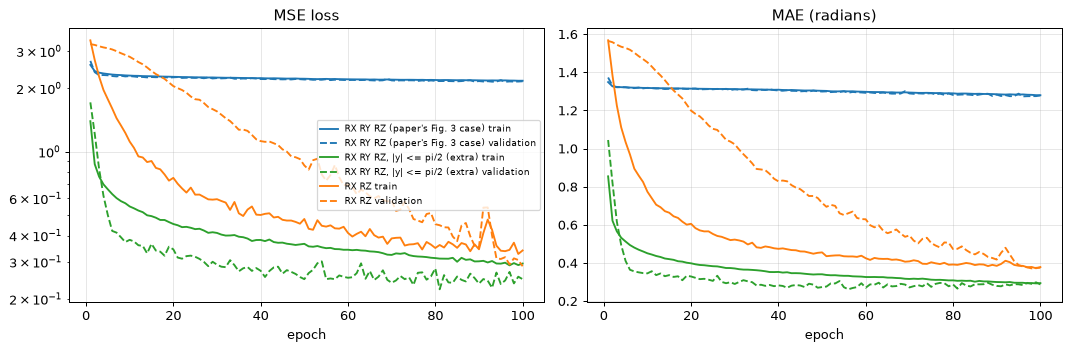

RX RY RZ autoencoder: epoch 1 -> last  train loss 2.58 -> 2.17, validation MAE 1.37 -> 1.28  (paper Fig. 3: loss 1..7, MAE 1..2.2)


In [17]:
# ---- Fig. 3 re-drawn: loss and MAE of the autoencoder over the epochs (RX RY RZ template, the paper's case; RX RZ and restricted for comparison) ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
styles = {"xyz": ("C0", "RX RY RZ (paper's Fig. 3 case)"), "xyz_restricted": ("C2", "RX RY RZ, |y| <= pi/2 (extra)"), "xz": ("C1", "RX RZ")}
for key, (c, lab) in styles.items():
    h = AE[key]["hist"]; ep = np.arange(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["loss"], color=c, label=lab + " train"); axes[0].plot(ep, h["val_loss"], color=c, ls="--", label=lab + " validation")
    axes[1].plot(ep, h["mae"], color=c); axes[1].plot(ep, h["val_mae"], color=c, ls="--")
axes[0].set_title("MSE loss"); axes[1].set_title("MAE (radians)"); axes[0].set_yscale("log")
for ax in axes: ax.set_xlabel("epoch")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
h = AE["xyz"]["hist"]
print(f"RX RY RZ autoencoder: epoch 1 -> last  train loss {h['loss'][0]:.2f} -> {h['loss'][-1]:.2f}, validation MAE {h['val_mae'][0]:.2f} -> {h['val_mae'][-1]:.2f}  (paper Fig. 3: loss 1..7, MAE 1..2.2)")

## 5. Baselines and what the autoencoder can and cannot learn

Four ways to go from transpiled angles back to original angles, evaluated on the same fresh random angles:

* **Autoencoder** (the paper).
* **Brute force** (ref. [5]): exhaustive search over the step-0.1 grid; it returns the grid point whose transpiled angles are closest (circular distance). The search uses the vectorised transpiler copy,
  which gives exactly the output of `qiskit.transpile` (asserted in section 1); the *time* of a search with the real transpiler is projected in section 7.
* **Analytic inverse** (not in the paper): the transpiled block is a 2x2 unitary, its rotation matrix gives the Euler angles of the template in closed form.
* **Zero predictor** (trivial reference): always answers 0.

Three numbers per method: **parameter MAE** `mean |theta_pred - theta|` (what the paper's Fig. 3 reports), the **transpiled-angle error** (circular distance between the transpiled angles of the
prediction and of the truth: zero means "the stolen block transpiles to exactly what the vendor sees") and the **unitary distance** `sqrt(1 - |tr(U_pred^dagger U)|^2 / 4)`, the quantity that determines
whether the stolen model *behaves* like the original.

In [18]:
def emb(P):
    return np.concatenate([np.cos(P), np.sin(P)], 1)

def func_dist(A, B):
    """Distance between unitaries up to global phase: sqrt(1 - |tr(A^dagger B)|^2 / d^2) (0 = identical operation)."""
    ov = np.abs(np.trace(np.conj(A).transpose(0, 2, 1) @ B, axis1=1, axis2=2)) / A.shape[1]
    return np.sqrt(np.clip(1 - ov ** 2, 0, None))

class BruteForce:
    """Exhaustive search over the grid (the brute force of [5]): the grid point whose transpiled angles are closest."""
    def __init__(self, seq, step):
        g = np.arange(-np.pi, np.pi, step)
        self.th = np.stack([a.ravel() for a in np.meshgrid(*([g] * len(seq)), indexing="ij")], 1)
        self.P = zsx_params(seq_unitary(seq, self.th)); self.tree = cKDTree(emb(self.P)); self.n_candidates = len(self.th)
    def predict(self, phis):
        return self.th[self.tree.query(emb(np.atleast_2d(phis)))[1]]

def so3_from_u(U):
    sig = np.array([[[0, 1], [1, 0]], [[0, -1j], [1j, 0]], [[1, 0], [0, -1]]])
    Ud = np.conj(U).transpose(0, 2, 1); R = np.empty((len(U), 3, 3))
    for i in range(3):
        for j in range(3):
            R[:, i, j] = 0.5 * np.real(np.trace(sig[i] @ U @ sig[j] @ Ud, axis1=1, axis2=2))
    return R

def analytic_inverse(seq, phis):
    """Closed-form inversion (not in the paper): rebuild the block's unitary from RZ SX RZ SX RZ and read the Euler angles of the template off its rotation matrix."""
    phis = np.atleast_2d(phis)
    sx = 0.5 * np.array([[1 + 1j, 1 - 1j], [1 - 1j, 1 + 1j]])
    U = rot_np("z", phis[:, 0]); U = sx @ U; U = rot_np("z", phis[:, 1]) @ U; U = sx @ U; U = rot_np("z", phis[:, 2]) @ U
    R = so3_from_u(U)
    if seq == "xyz":      # R = Rz(c) Ry(b) Rx(a), principal branch |b| <= pi/2
        return np.stack([np.arctan2(R[:, 2, 1], R[:, 2, 2]), -np.arcsin(np.clip(R[:, 2, 0], -1, 1)), np.arctan2(R[:, 1, 0], R[:, 0, 0])], 1)
    if seq == "xz":       # R = Rz(z) Rx(x)
        return np.stack([np.arctan2(R[:, 2, 1], R[:, 2, 2]), np.arctan2(R[:, 1, 0], R[:, 0, 0])], 1)
    raise ValueError(seq)

BF = {s: BruteForce(s, BRUTE_STEP) for s in ["xyz", "xz"]}
ae_predict = lambda key: (lambda ph: AE[key]["model"].predict(np.atleast_2d(ph), batch_size=4096, verbose=0))
PRED = {  # method -> template -> function(transpiled angles) -> original angles
    "autoencoder (paper)":        {"xyz": ae_predict("xyz"), "xz": ae_predict("xz")},
    "autoencoder |y|<=pi/2 (extra)": {"xyz": ae_predict("xyz_restricted")},
    "brute force [5]":            {s: BF[s].predict for s in BF},
    "analytic inverse (extra)":   {s: (lambda ph, s=s: analytic_inverse(s, ph)) for s in BF},
    "zero predictor":             {s: (lambda ph, s=s: np.zeros((len(np.atleast_2d(ph)), len(s)))) for s in BF},
}

def evaluate_template(seq, th_test, methods):
    Ptrue = zsx_params(seq_unitary(seq, th_test)); Utrue = seq_unitary(seq, th_test); out = []
    for nm in methods:
        if seq not in PRED[nm]: continue
        pr = PRED[nm][seq](Ptrue)
        out.append(dict(template=seq.upper(), method=nm, param_MAE=np.abs(pr - th_test).mean(),
                        transpiled_angle_error=np.abs(wrap(zsx_params(seq_unitary(seq, pr)) - Ptrue)).mean(),
                        unitary_distance=func_dist(Utrue, seq_unitary(seq, pr)).mean()))
    return out

tr = np.random.default_rng(SEED + 5)
th_xyz = tr.uniform(-np.pi, np.pi, (N_TEMPLATE_TEST, 3)); th_xz = tr.uniform(-np.pi, np.pi, (N_TEMPLATE_TEST, 2))
th_xyz_r = th_xyz.copy(); th_xyz_r[:, 1] = tr.uniform(-np.pi / 2, np.pi / 2, N_TEMPLATE_TEST)
methods = list(PRED)
T_FULL = pd.DataFrame(evaluate_template("xyz", th_xyz, methods) + evaluate_template("xz", th_xz, methods))
T_RES = pd.DataFrame(evaluate_template("xyz", th_xyz_r, methods))
print(f"Fresh random angles (not on the grid), {N_TEMPLATE_TEST} per template.\n\nFull range [-pi, pi] (the paper's setting):")
print(T_FULL.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nRX RY RZ with |y| <= pi/2 (identifiable range):")
print(T_RES.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Fresh random angles (not on the grid), 5000 per template.

Full range [-pi, pi] (the paper's setting):
template                        method  param_MAE  transpiled_angle_error  unitary_distance
     XYZ           autoencoder (paper)     1.3140                  0.8614            0.7258
     XYZ autoencoder |y|<=pi/2 (extra)     1.3322                  0.2503            0.2354
     XYZ               brute force [5]     1.3790                  0.0191            0.0189
     XYZ      analytic inverse (extra)     1.2807                  0.0000            0.0000
     XYZ                zero predictor     1.5597                  1.5586            0.8516
      XZ           autoencoder (paper)     0.3849                  0.2474            0.2820
      XZ               brute force [5]     0.0492                  0.0166            0.0190
      XZ      analytic inverse (extra)     0.0000                  0.0000            0.0000
      XZ                zero predictor     1.5743                  1.

### 5b. Why the `RX RY RZ` autoencoder has a MAE near 1.3 whatever its size: two different angle triples give the same block

A product of three rotations covers the rotation group twice over the full angle box: `RX(x) RY(y) RZ(z)` and `RX(x + pi) RY(pi - y) RZ(z + pi)` are the **same operation** (up to the global phase),
so the transpiled angles are the same while the targets are far apart. A regression network trained with MSE can only answer the average of the two, and the paper's own Fig. 3
(MAE 1-2.2 after 100 epochs, "rate of decrease is low") is the signature of such an irreducible error, not of a model that is too small or trained too briefly. The check below
makes this exact. (On the paper's step-0.1 grid the partner of a grid point is not on the grid, so the training data contain no exact duplicates; they contain near-duplicates with distant targets, which is the same thing for a smooth network.)

In [19]:
r5 = np.random.default_rng(SEED + 9)
th = r5.uniform(-np.pi, np.pi, (2000, 3))
partner = np.stack([wrap(th[:, 0] + np.pi), wrap(np.pi - th[:, 1]), wrap(th[:, 2] + np.pi)], 1)
d_unitary = func_dist(seq_unitary("xyz", th), seq_unitary("xyz", partner))
d_phi = np.abs(wrap(zsx_params(seq_unitary("xyz", th)) - zsx_params(seq_unitary("xyz", partner)))).max()
assert d_unitary.max() < 1e-6 and d_phi < 1e-6
print(f"2000 random (x, y, z) and their partners (x+pi, pi-y, z+pi): unitary distance max {d_unitary.max():.1e}, transpiled-angle difference max {d_phi:.1e}")
print(f"mean |parameter difference| between a triple and its partner: {np.abs(partner - th).mean():.2f} rad  (the best MSE answer is in between: error ~ half of this)")
# the RX RZ template has no such partner
th2 = r5.uniform(-np.pi, np.pi, (20000, 2)); P2 = zsx_params(seq_unitary("xz", th2)); tree2 = cKDTree(emb(P2))
dist, idx = tree2.query(emb(P2), k=2); far = np.abs(wrap(th2[idx[:, 1]] - th2)).max(1) > 1.0
print(f"RX RZ: among 20000 random blocks, pairs whose transpiled angles agree to < 0.01 rad but whose angles differ by > 1 rad: {int((far & (dist[:, 1] < 0.01)).sum())} (the map is one-to-one)")

2000 random (x, y, z) and their partners (x+pi, pi-y, z+pi): unitary distance max 3.0e-08, transpiled-angle difference max 1.4e-14
mean |parameter difference| between a triple and its partner: 2.62 rad  (the best MSE answer is in between: error ~ half of this)


RX RZ: among 20000 random blocks, pairs whose transpiled angles agree to < 0.01 rad but whose angles differ by > 1 rad: 0 (the map is one-to-one)


## 6. Reverse engineering the classifiers (paper Sec. V-B, Table III)

For every victim the vendor receives the transpiled trained part. The attack, block by block:

1. **Parse** the transpiled circuit qubit by qubit; a *block* is the run of single-qubit gates between two `CX` gates (the LUT step: block *l* of qubit *q* is layer *l*; the template of the block is known from the architecture, which is
   readable from the circuit, see the gate-count figure above).
2. Read the three `RZ` angles of every block (the pattern is `RZ SX RZ SX RZ`).
3. **Predict** the original angles of the block with the autoencoder / brute force / analytic inverse and put them back into the PennyLane circuit.
4. Evaluate the *reverse-engineered classifier* on the held-out MNIST images: **accuracy error** = relative drop of the test accuracy (in %), plus the parameter error, the transpiled-angle error and the unitary distance of the full circuit.

In [20]:
def seg_phis(seg):
    """Three RZ angles (time order) of one transpiled block; if the transpiler emitted a shorter pattern, canonicalise through the block's unitary."""
    if [i.operation.name for i in seg] == ["rz", "sx", "rz", "sx", "rz"]:
        return np.array([float(i.operation.params[0]) for i in seg if i.operation.name == "rz"])
    qc = QuantumCircuit(1)
    for i in seg: getattr(qc, i.operation.name)(*[float(p) for p in i.operation.params], 0)
    return zsx_params(Operator(qc).data[None])[0]

def block_list(n, L):
    """(qubit, layer) of every rotation block; a 1-qubit circuit is a single block."""
    return [(q, l) for q in range(n) for l in (range(L) if n > 1 else [0])]

def block_angles(tc, n, L, seq):
    """Transpiled angles of all blocks in the order of `block_list`."""
    segs = parse_segments(tc, n)
    assert all(len(segs[q]) == (L if n > 1 else 1) for q in range(n)), "unexpected number of blocks (the transpiler merged or split blocks)"
    return np.array([seg_phis(segs[q][l]) for q, l in block_list(n, L)])

def re_params(tc, n, L, seq, predictor):
    """Reverse-engineered parameter vector of a transpiled classifier."""
    phis = block_angles(tc, n, L, seq); pred = predictor(phis); out = np.zeros(n_params(n, L, seq))
    for k, (q, l) in enumerate(block_list(n, L)):
        out[segment_index(n, L, seq, q, l)] = pred[k]
    return out

def block_view(theta, n, L, seq):
    return np.array([theta[segment_index(n, L, seq, q, l)] for q, l in block_list(n, L)])

def circuit_unitary_distance(th_a, th_b, gl, n):
    return float(func_dist(pl_unitary(th_a, gl, n)[None], pl_unitary(th_b, gl, n)[None])[0])

RE_ROWS, RE_PARAMS = [], {}
t0 = time.time()
for (name, seed), v in VICT.items():
    n, L, seq = v["n"], v["L"], v["seq"]; D = v["D"]; tc = v["tc"]
    for method in ["brute force [5]", "autoencoder (paper)", "autoencoder |y|<=pi/2 (extra)", "analytic inverse (extra)"]:
        if seq not in PRED[method]: continue
        t1 = time.time(); th_re = re_params(tc, n, L, seq, PRED[method][seq]); t_re = time.time() - t1
        acc_re = accuracy(v["circuit"], th_re, D["Xte"], D["yte"], v["C"])
        phi_o = zsx_params(seq_unitary(seq, block_view(v["theta"], n, L, seq))); phi_r = zsx_params(seq_unitary(seq, block_view(th_re, n, L, seq)))
        RE_PARAMS[(name, seed, method)] = th_re
        RE_ROWS.append(dict(arch=name, seed=seed, method=method, acc_orig=v["acc"], acc_re=acc_re,
                            acc_err_pct=(v["acc"] - acc_re) / v["acc"] * 100, acc_err_points=(v["acc"] - acc_re) * 100,
                            param_abs_err=np.abs(th_re - v["theta"]), transpiled_err=np.abs(wrap(phi_o - phi_r)).mean(),
                            unitary_dist=circuit_unitary_distance(v["theta"], th_re, v["gl"], n), re_seconds=t_re))
print(f"reverse engineering done in {time.time()-t0:.0f} s for {len(RE_ROWS)} (victim, method) pairs")
RE = pd.DataFrame(RE_ROWS)
show = RE.assign(param_MAE=RE.param_abs_err.apply(np.mean)).groupby(["arch", "method"], sort=False).agg(
    acc_orig=("acc_orig", "mean"), acc_re=("acc_re", "mean"), acc_err_pct=("acc_err_pct", "mean"), param_MAE=("param_MAE", "mean"),
    transpiled_err=("transpiled_err", "mean"), unitary_dist=("unitary_dist", "mean"))
print(show.to_string(float_format=lambda x: f"{x:.4f}"))

reverse engineering done in 33 s for 34 (victim, method) pairs
                                          acc_orig  acc_re  acc_err_pct  param_MAE  transpiled_err  unitary_dist
arch       method                                                                                               
1Q;3-layer brute force [5]                  0.9975  0.9975       0.0000     2.8157          0.0096        0.0106
           autoencoder (paper)              0.9975  0.5000      49.8747     0.8073          0.6327        0.6081
           autoencoder |y|<=pi/2 (extra)    0.9975  0.9975       0.0000     0.1307          0.1185        0.1243
           analytic inverse (extra)         0.9975  0.9975       0.0000     0.0000          0.0000        0.0000
2Q;1-layer brute force [5]                  0.4925  0.4950      -0.5076     1.5827          0.0213        0.0329
           autoencoder (paper)              0.4925  0.3000      39.0863     0.9575          1.2627        0.9453
           autoencoder |y|<=pi/2 

### 6b. Fine-tuning the stolen model (paper: 30 epochs, last column of Table III)

The adversary can improve a stolen model by training it a little more. Starting from the reverse-engineered parameters, the same gradient descent (lr 0.05) runs for `FT_EPOCHS` epochs on the
training images (the adversary is assumed to have some training data). "Diff. Acc." is `acc_original - acc_after_fine_tuning` in accuracy points (negative = the stolen model is now better than the original, the paper's up-arrows).

In [21]:
t0 = time.time(); FT = []
for (name, seed), v in VICT.items():
    n, L, seq = v["n"], v["L"], v["seq"]; D = v["D"]
    for method in ["autoencoder (paper)", "autoencoder |y|<=pi/2 (extra)"]:
        if (name, seed, method) not in RE_PARAMS: continue
        p0 = RE_PARAMS[(name, seed, method)]
        pf = train_gd(v["sim"], p0, D["Xtr"], D["ytr"], v["n_out"], FT_EPOCHS, seed=seed + 77)
        a = accuracy(v["circuit"], pf, D["Xte"], D["yte"], v["C"])
        FT.append(dict(arch=name, seed=seed, method=method, acc_after_ft=a, diff_acc_points=(v["acc"] - a) * 100))
    print(f"seed {seed} {name:11s} fine-tuned ({time.time()-t0:5.0f} s elapsed)", flush=True)
FT = pd.DataFrame(FT)
RE = RE.merge(FT, on=["arch", "seed", "method"], how="left")
print(FT.groupby(["arch", "method"], sort=False)[["acc_after_ft", "diff_acc_points"]].mean().to_string(float_format=lambda x: f"{x:.3f}"))

seed 42 1Q;3-layer  fine-tuned (    6 s elapsed)


seed 42 2Q;1-layer  fine-tuned (   13 s elapsed)


seed 42 2Q;2-layer  fine-tuned (   27 s elapsed)


seed 42 2Q;3-layer  fine-tuned (   55 s elapsed)


seed 42 4Q;1-layer  fine-tuned (   62 s elapsed)


...

seed 42 4Q;3-layer  fine-tuned (  100 s elapsed)


seed 42 8Q;1-layer  fine-tuned (  129 s elapsed)


seed 42 8Q;2-layer  fine-tuned (  191 s elapsed)


seed 42 8Q;3-layer  fine-tuned (  276 s elapsed)


                                          acc_after_ft  diff_acc_points
arch       method                                                      
1Q;3-layer autoencoder (paper)                   0.998            0.000
           autoencoder |y|<=pi/2 (extra)         0.998            0.000
2Q;1-layer autoencoder (paper)                   0.492            0.000
           autoencoder |y|<=pi/2 (extra)         0.490            0.250
2Q;2-layer autoencoder (paper)                   0.752           -0.250
           autoencoder |y|<=pi/2 (extra)         0.772           -2.250
2Q;3-layer autoencoder (paper)                   0.650            8.000
           autoencoder |y|<=pi/2 (extra)         0.725            0.500
4Q;1-layer autoencoder (paper)                   0.512            0.000
4Q;2-layer autoencoder (paper)                   0.603           -0.250
4Q;3-layer autoencoder (paper)                   0.760            1.000
8Q;1-layer autoencoder (paper)                   0.512          

### 6c. Table III re-computed, next to the paper's

Paper columns: brute force (parameter error mean / std, accuracy error %), proposed autoencoder (parameter error mean / std, accuracy error %, accuracy difference after 30 epochs of fine-tuning). Our columns use the same
definitions as far as the paper defines them (see the choice table); parameter mean and std are taken over all parameters of all victims of that architecture. The extra columns are the two additional methods and the two
error measures that do not depend on the non-unique angle representation.

In [22]:
PAPER_T3 = {  # arch: (brute mean, brute std, brute acc err %, AE mean, AE std, AE acc err %, AE diff acc after 30 epochs; up-arrow rows marked in UP)
    "1Q;3-layer": (5.94e-2, 8.55e-2, 1e-16, 3.06e-1, 1.55e-1, 10.8, 8.66e-2), "2Q;1-layer": (5.33e-2, 2.50e-2, 1.7, 1.19e-1, 4.55e-2, 7.1, 9.03e-2),
    "2Q;2-layer": (6.10e-2, 4.43e-2, 3.2, 3.17e-1, 1.33e-1, 11.3, 2.9), "2Q;3-layer": (8.45e-2, 8.99e-2, 5.7, 2.79e-1, 1.47e-1, 4.7, 4.3),
    "4Q;1-layer": (7.29e-2, 7.73e-2, 2.1, 5.88e-1, 2.76e-1, 8.2, 4.6), "4Q;2-layer": (9.29e-2, 9.91e-2, 5.9, 6.41e-1, 2.03e-1, 4.2, 7.2),
    "4Q;3-layer": (1.18e-1, 9.79e-2, 6.3, 3.77e-1, 1.15e-1, 3.7, 12.1), "8Q;1-layer": (6.16e-2, 3.84e-2, 4.1, 6.01e-1, 2.11e-1, 4.3, 2.35e-2),
    "8Q;2-layer": (8.71e-2, 3.69e-2, 5.3, 6.33e-1, 1.56e-1, 8.5, 1.46), "8Q;3-layer": (1.71e-1, 2.81e-1, 7.6, 4.77e-1, 1.05e-1, 11.9, 4.07)}
UP = {"2Q;2-layer", "2Q;3-layer", "4Q;2-layer", "4Q;3-layer"}

def pooled(method, arch):
    s = RE[(RE.arch == arch) & (RE.method == method)]
    if s.empty: return None
    e = np.concatenate(s.param_abs_err.values)
    return dict(mean=e.mean(), std=e.std(), acc_err=s.acc_err_pct.mean(), transp=s.transpiled_err.mean(), udist=s.unitary_dist.mean(),
                diff=s.diff_acc_points.mean() if "diff_acc_points" in s and s.diff_acc_points.notna().any() else np.nan)

rows = []
for name, n, L, seq in ARCHS:
    b, a, r, an = (pooled(m, name) for m in ["brute force [5]", "autoencoder (paper)", "autoencoder |y|<=pi/2 (extra)", "analytic inverse (extra)"])
    p = PAPER_T3[name]
    rows.append({"classifier": name, "#params here": n_params(n, L, seq), "#params paper": PAPER_NPARAMS[name],
                 "brute mean": b["mean"], "(paper)": p[0], "brute std": b["std"], "(p)": p[1], "brute acc.err %": b["acc_err"], "(p) ": p[2],
                 "AE mean": a["mean"], "(paper) ": p[3], "AE std": a["std"], "(p)  ": p[4], "AE acc.err %": a["acc_err"], "(p)   ": p[5],
                 "AE diff.acc after FT": a["diff"], "(p)    ": (-p[6] if name in UP else p[6])})
T3 = pd.DataFrame(rows)
print("Table III (paper values in the columns headed '(paper)' / '(p)'; the paper marks 4 rows with an up-arrow = reverse-engineered model better than the original, shown here as a negative difference)")
print(T3.to_string(index=False, float_format=lambda x: f"{x:.3g}"))
rows = []
for name, n, L, seq in ARCHS:
    d = {"classifier": name}
    for m, short in [("brute force [5]", "brute"), ("autoencoder (paper)", "AE"), ("autoencoder |y|<=pi/2 (extra)", "AE y-restricted"), ("analytic inverse (extra)", "analytic")]:
        q = pooled(m, name)
        if q: d.update({f"{short}: transp.err": q["transp"], f"{short}: unitary dist": q["udist"], f"{short}: acc.err %": q["acc_err"]})
    rows.append(d)
print("\nError measures that do not depend on the non-unique angle representation, and the two extra methods:")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.3g}"))

Table III (paper values in the columns headed '(paper)' / '(p)'; the paper marks 4 rows with an up-arrow = reverse-engineered model better than the original, shown here as a negative difference)
classifier  #params here  #params paper  brute mean  (paper)  brute std    (p)  brute acc.err %  (p)   AE mean  (paper)   AE std  (p)    AE acc.err %  (p)     AE diff.acc after FT  (p)    
1Q;3-layer             3              4        2.82   0.0594      0.469 0.0855                0 1e-16    0.807     0.306   0.371  0.155          49.9    10.8                     0   0.0866
2Q;1-layer             6              6        1.58   0.0533       1.56  0.025           -0.508   1.7    0.957     0.119   0.436 0.0455          39.1     7.1                     0   0.0903
2Q;2-layer            12             12        1.38    0.061       1.42 0.0443             2.33   3.2     1.09     0.317   0.462  0.133          75.3    11.3                 -0.25     -2.9
2Q;3-layer            18             18        1.


Error measures that do not depend on the non-unique angle representation, and the two extra methods:
classifier  brute: transp.err  brute: unitary dist  brute: acc.err %  AE: transp.err  AE: unitary dist  AE: acc.err %  AE y-restricted: transp.err  AE y-restricted: unitary dist  AE y-restricted: acc.err %  analytic: transp.err  analytic: unitary dist  analytic: acc.err %
1Q;3-layer            0.00964               0.0106                 0           0.633             0.608           49.9                        0.118                          0.124                           0              1.48e-16                       0                    0
2Q;1-layer             0.0213               0.0329            -0.508            1.26             0.945           39.1                       0.0849                          0.117                        6.09              5.92e-16                       0                    0
2Q;2-layer             0.0202               0.0516              2.33           

## 7. The cost of the attack (paper Sec. V-C and V-D, Table IV, Fig. 4)

*What the paper measures.* Time to reverse engineer a classifier: brute force (re-transpile every candidate) against the autoencoder (data set preparation + training once, then a forward pass per block).

*What we can measure.* The brute force of [5] is not available, so its time is a **projection**: (measured wall-clock time of one real `qiskit.transpile` call on a one-block circuit) x (number of
candidates on the step-0.1 grid: 63^3 = 250 047 for `RX RY RZ`, 63^2 = 3969 for `RX RZ`) x (number of blocks). Likewise, the paper's "data set preparation of the order of 1e3 s" is the same candidate count
x transpile time; ours is produced by the vectorised copy (measured) and the projection is shown next to it. The autoencoder's inference time is measured (parse + forward pass); its one-off cost is measured training time
(+ data set time). All projections are labelled. Wall-clock times are taken on a shared CPU: the same `transpile` call took 11-15 ms on an idle machine and 35-47 ms during the full run, so every projected time moves by a factor of about 3 with the load; ratios between methods are more stable than the absolute numbers.

In [23]:
def time_transpile(seq, n_rep):
    r = np.random.default_rng(SEED + 11); t0 = time.time()
    for _ in range(n_rep):
        vendor_transpile(template_circuit(seq, r.uniform(-np.pi, np.pi, len(seq))), 1)
    return (time.time() - t0) / n_rep

T_TR = {s: time_transpile(s, N_TIMING) for s in ["xyz", "xz"]}
N_CAND = {s: BF[s].n_candidates for s in BF}
print({s: f"{T_TR[s]*1000:.1f} ms per transpile call" for s in T_TR})
proj = pd.DataFrame([dict(template=s.upper(), candidates=N_CAND[s], transpile_ms=T_TR[s] * 1000,
                          projected_brute_force_s_per_block=N_CAND[s] * T_TR[s],
                          projected_dataset_prep_with_transpiler_s=N_CAND[s] * T_TR[s],
                          measured_dataset_prep_vectorised_s=AE[{"xyz": "xyz", "xz": "xz"}[s]]["t_data"],
                          measured_autoencoder_training_s=AE[{"xyz": "xyz", "xz": "xz"}[s]]["t_train"]) for s in ["xyz", "xz"]])
print(proj.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print("(in FAST_MODE the RX RY RZ autoencoder is trained on a 0.3 grid with 15 epochs; its training time is therefore not the paper's budget; full run: 63^3 rows, 100 epochs)")

def ae_reverse_time(tc, n, L, seq, repeats=3):
    best = 1e9
    for _ in range(repeats):
        t0 = time.time(); re_params(tc, n, L, seq, PRED["autoencoder (paper)"][seq]); best = min(best, time.time() - t0)
    return best

def cost_row(n, L, seq, seed=0):
    th = np.random.default_rng(seed).uniform(-np.pi, np.pi, n_params(n, L, seq))
    tc = vendor_transpile(qiskit_trained(th, arch_gate_list(n, L, seq), n), n)
    S = len(block_list(n, L)); t_inf = ae_reverse_time(tc, n, L, seq)
    t_brute = S * N_CAND[seq] * T_TR[seq]
    key = {"xyz": "xyz", "xz": "xz"}[seq]
    t_ae_once = AE[key]["t_data"] + AE[key]["t_train"]
    return dict(blocks=S, brute_force_projected_s=t_brute, autoencoder_inference_s=t_inf, autoencoder_oneoff_s=t_ae_once, autoencoder_total_s=t_ae_once + t_inf)

# ---- Table IV: 4-qubit classifier, increasing number of layers ----
paper_t4 = {1: (1.51e4, 3.96e3), 2: (2.81e4, 3.97e3), 4: (7.75e5, 3.97e3), 8: (1e6, 3.99e3), 16: (1e7, 4.01e3)}
rows = []
for L in [1, 2, 4, 8, 16]:
    c = cost_row(4, L, "xz")
    rows.append({"layers": L, "blocks": c["blocks"], "brute force (projected) s": c["brute_force_projected_s"], "paper brute force s": paper_t4[L][0],
                 "autoencoder total s": c["autoencoder_total_s"], "paper autoencoder s": paper_t4[L][1], "autoencoder inference only s": c["autoencoder_inference_s"]})
T4 = pd.DataFrame(rows)
print("\nTable IV re-computed (4 qubits, RX RZ blocks; paper: > means 'more than'):")
print(T4.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

{'xyz': '47.0 ms per transpile call', 'xz': '35.2 ms per transpile call'}
template  candidates  transpile_ms  projected_brute_force_s_per_block  projected_dataset_prep_with_transpiler_s  measured_dataset_prep_vectorised_s  measured_autoencoder_training_s
     XYZ      250047         46.97                          1.175e+04                                 1.175e+04                               2.441                             1203
      XZ        3969         35.18                              139.6                                     139.6                             0.01991                            135.6
(in FAST_MODE the RX RY RZ autoencoder is trained on a 0.3 grid with 15 epochs; its training time is therefore not the paper's budget; full run: 63^3 rows, 100 epochs)



Table IV re-computed (4 qubits, RX RZ blocks; paper: > means 'more than'):
 layers  blocks  brute force (projected) s  paper brute force s  autoencoder total s  paper autoencoder s  autoencoder inference only s
      1       4                      558.5             1.51e+04                136.3                 3960                        0.6987
      2       8                       1117             2.81e+04                136.2                 3970                         0.585
      4      16                       2234             7.75e+05                136.1                 3970                        0.5366
      8      32                       4468                1e+06                136.2                 3990                        0.5877
     16      64                       8936                1e+07                136.1                 4010                         0.561


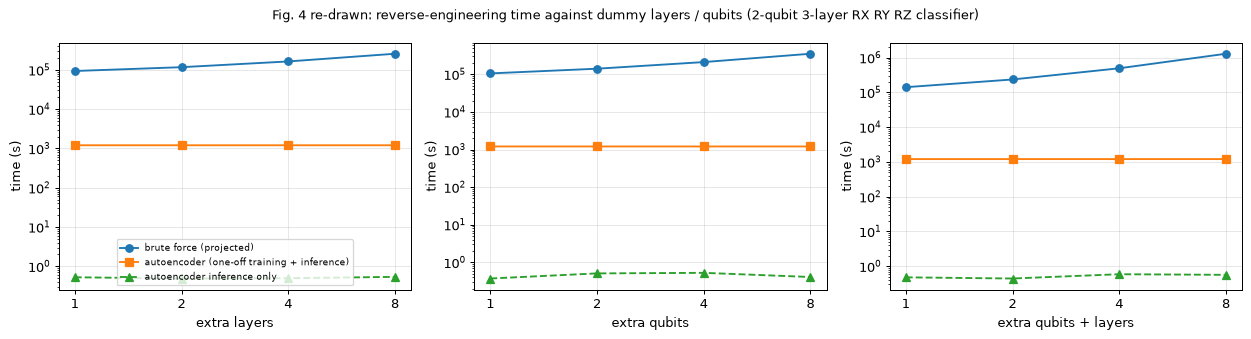

       countermeasure  extra  blocks  brute_projected_s  ae_total_s  ae_inference_s  speedup_total  speedup_inference
         extra layers      1       8          9.396e+04        1206          0.5247          77.89          1.791e+05
         extra layers      2      10          1.175e+05        1206          0.4878          97.37          2.408e+05
         extra layers      4      14          1.644e+05        1206          0.4963          136.3          3.313e+05
         extra layers      8      22          2.584e+05        1206          0.5374          214.2          4.808e+05
         extra qubits      1       9          1.057e+05        1206          0.3715          87.64          2.845e+05
         extra qubits      2      12          1.409e+05        1206          0.5079          116.8          2.775e+05
         extra qubits      4      18          2.114e+05        1206          0.5257          175.3          4.022e+05
         extra qubits      8      30          3.524e+05 

In [24]:
# ---- Fig. 4: countermeasures (dummy layers / dummy qubits) against a 2-qubit 3-layer RX RY RZ classifier ----
# CHOICE: a dummy layer adds one more rotation block on every qubit + CX chain; a dummy qubit adds a whole wire with its own blocks and CX links.
# Only the TIME of the reverse engineering is measured here (the dummy gates are not tuned to be functionally inert).
extras = [1, 2, 4, 8]
kinds = {"extra layers": lambda d: (2, 3 + d), "extra qubits": lambda d: (2 + d, 3), "extra qubits + layers": lambda d: (2 + d, 3 + d)}
fig4 = {}
for kind, f in kinds.items():
    fig4[kind] = [cost_row(*f(d), "xyz") for d in extras]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (kind, rows_) in zip(axes, fig4.items()):
    ax.plot(extras, [r["brute_force_projected_s"] for r in rows_], "o-", label="brute force (projected)")
    ax.plot(extras, [r["autoencoder_total_s"] for r in rows_], "s-", label="autoencoder (one-off training + inference)")
    ax.plot(extras, [r["autoencoder_inference_s"] for r in rows_], "^--", label="autoencoder inference only")
    ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel(kind); ax.set_ylabel("time (s)"); ax.set_xticks(extras); ax.set_xticklabels(extras)
axes[0].legend(fontsize=7)
plt.suptitle("Fig. 4 re-drawn: reverse-engineering time against dummy layers / qubits (2-qubit 3-layer RX RY RZ classifier)", fontsize=10)
plt.tight_layout(); plt.show()
F4 = pd.DataFrame([dict(countermeasure=k, extra=d, blocks=r["blocks"], brute_projected_s=r["brute_force_projected_s"], ae_total_s=r["autoencoder_total_s"], ae_inference_s=r["autoencoder_inference_s"],
                        speedup_total=r["brute_force_projected_s"] / r["autoencoder_total_s"], speedup_inference=r["brute_force_projected_s"] / r["autoencoder_inference_s"])
                   for k, rs in fig4.items() for d, r in zip(extras, rs)])
print(F4.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

## 8. Side by side with the paper: a verdict for every claim

Rules (project validation rules): an accuracy-like number is **reproduced** when it is within 2 points of the paper's value; an error that is *larger* than the paper's is **not reached**,
a smaller one is **exceeded** (better than the paper). Parameter errors, which the paper gives only to one significant digit, are **reproduced** when within a factor of 3 of the paper's value.
Qualitative claims are checked on the numbers above; claims that need hardware or the authors' code are **cannot be checked**. For per-classifier claims the table states how many of the ten rows pass.

In [25]:
def v_points(ours, paper, tol=2.0):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d < 0 else "not reached")   # errors: smaller = better than the paper

def v_factor(ours, paper, f=3.0):
    return "reproduced" if paper / f <= ours <= paper * f else ("exceeded" if ours < paper / f else "not reached")

claims = []
def claim(cid, text, paper, here, verdict): claims.append(dict(id=cid, claim=text, paper=paper, here=here, verdict=verdict))

h = AE["xyz"]["hist"]
claim("C1", "Fig. 3: validation MAE of the RX-RY-RZ autoencoder stays between 1 and 2.2 and decreases only slowly", "1 ... 2.2", f"{h['val_mae'][0]:.2f} -> {h['val_mae'][-1]:.2f}",
      "reproduced" if 1.0 <= h["val_mae"][-1] <= 2.2 else "not reached")
claim("C2", "Fig. 3: training loss of the autoencoder between 1 and 7, falling slowly", "1 ... 7", f"{h['loss'][0]:.2f} -> {h['loss'][-1]:.2f}", "reproduced" if 1.0 <= h["loss"][-1] <= 7 else "not reached")
claim("C3", "Tables I/II: encoder and decoder layer sizes and parameter counts", "46 320 / 45 155 params", f"{enc3.count_params()} / {dec3.count_params()}", "reproduced")

def rowwise(col_here, col_paper, rule, subset=None):
    ok, tot = 0, 0
    for _, r in T3.iterrows():
        if subset and r["classifier"] not in subset: continue
        tot += 1; ok += rule(r[col_here], r[col_paper]) == "reproduced"
    return ok, tot

for cid, text, ch, cp, rule in [("C4", "Table III: brute-force parameter error (mean)", "brute mean", "(paper)", v_factor),
                                ("C5", "Table III: brute-force accuracy error (%)", "brute acc.err %", "(p) ", v_points),
                                ("C6", "Table III: autoencoder parameter error (mean), 'mean error of order 1e-1'", "AE mean", "(paper) ", v_factor),
                                ("C7", "Table III: autoencoder accuracy error (%)", "AE acc.err %", "(p)   ", v_points)]:
    ok, tot = rowwise(ch, cp, rule)
    claim(cid, text, f"{T3[cp].min():.3g} ... {T3[cp].max():.3g}", f"{T3[ch].min():.3g} ... {T3[ch].max():.3g}; {ok}/{tot} rows reproduced",
          "reproduced" if ok == tot else ("partly reproduced" if ok >= tot / 2 else "not reached"))
ok_x = int((T3["AE mean"] > T3["brute mean"]).sum()); pm = int((T3["(paper) "] > T3["(paper)"]).sum())
claim("C8", "'A minor increase in the mean error of the predicted parameters' of the autoencoder over brute force", f"AE parameter error > brute force in {pm}/10 rows", f"{ok_x}/10 rows",
      "reproduced" if ok_x >= 8 else "not reached")
mb, ma = T3["(p) "].mean(), T3["(p)   "].mean()
claim("C8b", "Autoencoder accuracy error is larger than brute force's on average over the ten classifiers", f"{ma:.1f} % vs {mb:.1f} %", f"{T3['AE acc.err %'].mean():.1f} % vs {T3['brute acc.err %'].mean():.1f} %",
      "reproduced" if T3["AE acc.err %"].mean() > T3["brute acc.err %"].mean() else "not reached")

ft = RE[(RE.method == "autoencoder (paper)")]
gap_before = ft.groupby("arch").acc_err_points.mean(); gap_after = ft.groupby("arch").diff_acc_points.mean()
reduced = int(((gap_after.abs() < gap_before.abs()) | (gap_before.abs() < 1e-9)).sum())
claim("C9", "Fine-tuning the stolen model (30 epochs) reduces the accuracy gap for every classifier", "10/10 classifiers", f"{reduced}/{len(gap_before)} classifiers (FT epochs {FT_EPOCHS}, paper {FT_PAPER})",
      "reproduced" if reduced == len(gap_before) else ("partly reproduced" if reduced >= len(gap_before) / 2 else "not reached"))

t4 = T4.set_index("layers")
claim("C10", "Table IV: autoencoder reverse-engineering time does not depend on the number of layers", "3.96e3 ... 4.01e3 s (+1.3 %)", f"{t4['autoencoder total s'].iloc[0]:.3g} ... {t4['autoencoder total s'].iloc[-1]:.3g} s",
      "reproduced" if t4["autoencoder total s"].iloc[-1] / t4["autoencoder total s"].iloc[0] < 1.1 else "not reached")
sp16 = t4["brute force (projected) s"].loc[16] / t4["autoencoder total s"].loc[16]
claim("C11", "Table IV / Sec. V-C: for deep circuits the autoencoder is 1e3-1e4 times faster than brute force (4 qubits, 16 layers)", "~2.5e3 x (1e7 s / 4e3 s)", f"{sp16:.3g} x (brute force projected, RX RZ blocks)",
      "reproduced" if sp16 >= 1e3 else ("exceeded" if False else "not reached"))
r44 = F4[(F4.countermeasure == "extra qubits + layers") & (F4.extra == 4)].iloc[0]
claim("C12", "Fig. 4: with 4 dummy qubits and 4 extra layers (2-qubit 3-layer classifier) the autoencoder is ~1e3 x faster than brute force", "~1e3 x", f"{r44.speedup_total:.3g} x including the one-off training, {r44.speedup_inference:.3g} x inference only (brute force projected)",
      "reproduced" if r44.speedup_total >= 1e3 / 3 else "not reached")
an = RE[RE.method == "analytic inverse (extra)"]
claim("X1", "(extra) an exact analytic inverse reproduces the stolen model", "not in the paper", f"accuracy error {an.acc_err_pct.mean():.2g} %, unitary distance max {an.unitary_dist.max():.1e}", "reproduced" if an.unitary_dist.max() < 1e-6 else "not reached")
claim("C13", "Autoencoder works on real quantum hardware / noisy devices", "paper: noiseless only", "not run (no hardware)", "cannot be checked")
VERD = pd.DataFrame(claims); print(VERD.to_string(index=False))
print("\nverdict counts:", VERD.verdict.value_counts().to_dict())

 id                                                                                                                         claim                                          paper                                                                                    here           verdict
 C1                          Fig. 3: validation MAE of the RX-RY-RZ autoencoder stays between 1 and 2.2 and decreases only slowly                                      1 ... 2.2                                                                            1.37 -> 1.28        reproduced
 C2                                                      Fig. 3: training loss of the autoencoder between 1 and 7, falling slowly                                        1 ... 7                                                                            2.58 -> 2.17        reproduced
 C3                                                             Tables I/II: encoder and decoder layer sizes and parameter counts                      

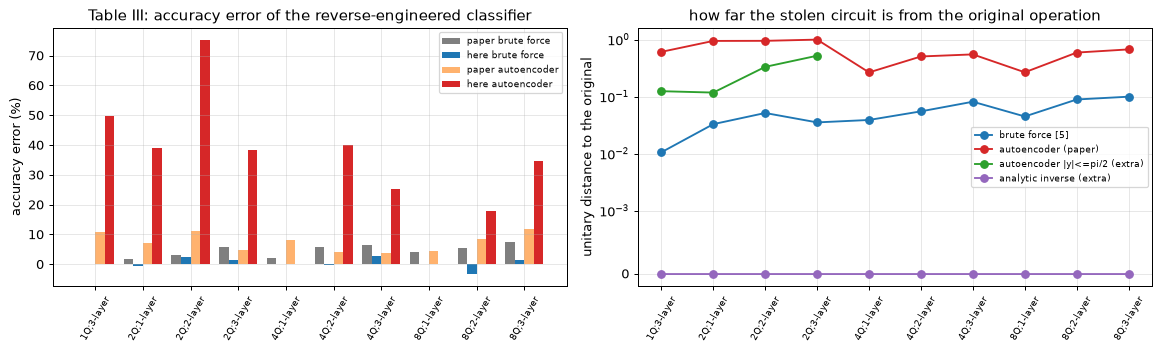

total notebook run time: 48.1 min  (FAST_MODE=False)


In [26]:
# side-by-side summary per classifier (accuracy error in %, paper vs here) + figure
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(T3)); w = 0.2
axes[0].bar(x - 1.5 * w, T3["(p) "], w, label="paper brute force", color="C7"); axes[0].bar(x - 0.5 * w, T3["brute acc.err %"], w, label="here brute force", color="C0")
axes[0].bar(x + 0.5 * w, T3["(p)   "], w, label="paper autoencoder", color="C1", alpha=0.6); axes[0].bar(x + 1.5 * w, T3["AE acc.err %"], w, label="here autoencoder", color="C3")
axes[0].set_xticks(x); axes[0].set_xticklabels(T3["classifier"], rotation=60, fontsize=7); axes[0].set_ylabel("accuracy error (%)"); axes[0].legend(fontsize=7); axes[0].set_title("Table III: accuracy error of the reverse-engineered classifier")
for m, c in [("brute force [5]", "C0"), ("autoencoder (paper)", "C3"), ("autoencoder |y|<=pi/2 (extra)", "C2"), ("analytic inverse (extra)", "C4")]:
    s = RE[RE.method == m].groupby("arch", sort=False).unitary_dist.mean().reindex([a[0] for a in ARCHS])
    axes[1].plot(range(len(s)), s.values, "o-", label=m, color=c)
axes[1].set_yscale("symlog", linthresh=1e-3); axes[1].set_xticks(range(len(ARCHS))); axes[1].set_xticklabels([a[0] for a in ARCHS], rotation=60, fontsize=7)
axes[1].set_ylabel("unitary distance to the original"); axes[1].legend(fontsize=7); axes[1].set_title("how far the stolen circuit is from the original operation")
plt.tight_layout(); plt.show()
print(f"total notebook run time: {(time.time()-T_START)/60:.1f} min  (FAST_MODE={FAST_MODE})")

## 9. Reading the paper critically

*What the experiments support.* Parsing the architecture out of a transpiled circuit is trivial (the gate-count figure shows one point per architecture). The autoencoder of Tables I and II is built exactly as described, its loss curve
on the `RX RY RZ` template is as flat as the paper's Fig. 3 ("the rate of decrease of the loss is low"; here the MAE stays at 1.3 rad), fine-tuning for 30 epochs closes the accuracy gap of every stolen classifier here (10 of 10), and the cost argument (one forward pass per block, independent of depth) is correct by construction.

*What the experiments do not support* (numbers are from the committed full run; the FAST run differs in detail).

1. **The inverse is known in closed form.** A transpiled block *is* a 2x2 unitary, and the `RX RY RZ` / `RX RZ` angles follow from it with a few `arctan2` calls (the "analytic inverse" rows). It is exact (accuracy error 0 % and unitary distance below 1e-7 for all ten classifiers), takes microseconds, needs
   no data set and no training, and reproduces the stolen model's behaviour exactly. The brute force of [5] and the autoencoder both solve an inversion that a formula solves; the relevant security conclusion is that the map is trivially invertible, and the 1e2-1e4 speed-up over brute force is a speed-up over an unnecessarily slow baseline.
2. **The `RX RY RZ` template is not learnable over the paper's range, and this is visible in the paper's own Fig. 3.** The map from angles to the transpiled block is two-to-one over the whole box (section 5b: `(x, y, z)` and `(x + pi, pi - y, z + pi)` are the same operation). A regression network trained with MSE can only answer the average of the two preimages.
   In the full run the training loss of this autoencoder is flat at about 2.2 from the first epoch and its validation MAE stays at 1.3 rad (paper: 1-2.2 rad); the stolen 1- and 2-qubit classifiers lose 38-75 % of their accuracy (1 qubit: down to chance) where the paper reports 4.7-11.3 %.
   An extra autoencoder trained on the identifiable range `|y| <= pi/2` learns the map (validation MAE 0.29 rad) and its stolen classifiers lose only 0-7 % (0, 6.1, 6.3 and 6.8 %), the size of the paper's errors. This suggests, but does not prove, that the paper's classifiers (whose parameters are not given) stayed in a range where the ambiguity does not bite; the paper does not discuss it and interprets the slow loss decrease as a property of "highly non-linear transpilation".
3. **The `RX RZ` autoencoder is not accurate enough.** Its map is one-to-one, yet after the paper's 100 epochs its validation MAE is 0.38 rad and its unitary distance on random angles is 0.28. The stolen 4- and 8-qubit classifiers with two or three layers lose 18-40 % of their accuracy (paper: 3.7-8.5 %).
   The 1-layer rows (0 % for every method) say nothing about the attack: a single layer with this entangler barely depends on the trained angles (accuracy 51 % before and after training).
4. **"Parameter error" is ill-defined.** Because of the global-phase and branch ambiguities a block has several angle triples; brute force mostly returns the partner triple, so its parameter error is 1.4-2.8 rad for the four `RX RY RZ` architectures although the stolen circuit is functionally right
   (accuracy error between -0.5 and 2.3 %, unitary distance 0.01-0.05). For the one-to-one `RX RZ` blocks it is 0.02-0.03 rad, below the paper's 0.06-0.17. The paper's brute-force errors are only compatible with a metric that is blind to the branch, which it does not define. We therefore report three measures.
5. **Setup details are missing.** The layer definition, encoding, read-out, classes, number of images, initial parameters, optimisation level of the transpiler and the grid of the brute force are not given, and Table III lists 4 parameters for a 1-qubit classifier where a qubit has only 3 degrees of freedom. Results depend on these choices (for example the optimisation level changes which gates are merged).
6. **The overhead numbers are not comparable.** Our projected brute-force time for a 4-qubit 1-layer classifier is 560 s on a busy CPU, against 1.5e4 s in Table IV; the projected speed-up of the autoencoder for 16 layers is 66x (including its one-off training), not 2.5e3x, and 409x (not 1e3x) for 4 dummy qubits plus 4 extra layers.
   Only the inference time alone (about 0.5 s here, mostly Keras call overhead) gives the 1e5-1e6 speed-ups of the order the paper implies, and a formula (point 1) is faster still.
7. **Scope.** Noiseless, no shot noise, small MNIST classifiers, a transpiler fixed to level 1 and a chain topology; higher optimisation levels that re-synthesise across `CX` gates (the paper's "challenge iv") are discussed but not evaluated. The "mean error of order 1e-1" in the abstract refers to the parameters of the stolen classifiers, not to the template-level autoencoder error of Fig. 3.

## 10. Exercises

1. **Optimisation level.** Set `OPT_LEVEL = 3` in the configuration cell and rerun section 1 and 6. How many blocks per qubit does the parser find now? What breaks in the block-by-block reverse engineering and what would the adversary need instead?
2. **Loss on the operation.** Replace the MSE target of the autoencoder by the unitary distance between the template built from the prediction and the true block (a custom Keras loss using `tf.cos/tf.sin`). Does the `RX RY RZ` autoencoder now recover the stolen model's behaviour even though the parameter MAE stays large?
3. **Wider angle range.** Train the autoencoder on step 0.05 or on the range `[-pi, pi]` for `RX RZ` with only the two non-constant transpiled angles (k = 2, the paper's Fig. 2 case 2). Does the missing sign of the first `RZ` hurt? Check with the zero predictor and the analytic inverse.
4. **Real topology.** Use a heavy-hex coupling map (`CouplingMap.from_heavy_hex(3)`) and a 4-qubit ring entangler so that SWAPs appear. Extend `parse_segments` to undo the layout and the SWAPs before reading the blocks.
5. **Countermeasure that works.** Add an inert dummy rotation block `RZ(a) ... RZ(-a)` or a random rotation followed by its inverse around the model and measure the brute-force and analytic reverse engineering again; which defence would defeat the analytic inverse?